## Figure 1 — The Frequency Dipole / Optimal Prior Direction

Defines the optimal-prior direction $d^*$ from empirical token frequencies,
compares candidate directions ($R^2$ diagnostics), shows the BOS prediction vs
the empirical unigram prior, and visualizes the dipole in the PCA plane of the
output embedding.

In [1]:
import os

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Self-contained layout: direction_of_prior/{scripts, data, notebook_plotters}
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebook_plotters" else cwd
SCRIPTS_DIR = ROOT / "scripts"
DATA_DIR = ROOT / "data"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import utils
import pile_token_stats
import dipole_utils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
model_name = "meta-llama/Llama-3.2-3B"
# model_name = "meta-llama/Llama-3.2-1B"
# model_name = "meta-llama/Llama-3.1-8B"
# model_name = "Qwen/Qwen2.5-1.5B"
# model_name = "Qwen/Qwen2.5-3B"
# model_name = "google/gemma-3-1b-pt"
# model_name = "google/gemma-3-4b-pt"

model = AutoModelForCausalLM.from_pretrained(model_name).to(device)
tokenizer = AutoTokenizer.from_pretrained(model_name)
model.eval()


def get_transformer_backbone(causal_lm):
    """Return the decoder/backbone module for common HF causal LM wrappers."""
    for attr in ("model", "gpt_neox", "transformer"):
        backbone = getattr(causal_lm, attr, None)
        if backbone is not None and backbone is not causal_lm:
            return backbone
    return None


def forward_backbone(input_ids):
    """Forward input_ids through the LM backbone and expose last_hidden_state."""
    backbone = get_transformer_backbone(model)
    if backbone is not None:
        return backbone(input_ids)

    # Fallback for architectures without an obvious backbone attribute.
    from types import SimpleNamespace
    outputs = model(input_ids, output_hidden_states=True, use_cache=False)
    if outputs.hidden_states is None:
        raise RuntimeError("Could not obtain hidden states from this model.")
    return SimpleNamespace(last_hidden_state=outputs.hidden_states[-1])

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

In [3]:
#######################################################
##### Hyper-parameters for calculating token frequency
#######################################################

p_zipf_from_pile = True
zipf_alpha = 1
vocab_coverage = 0.7

#######################################################
##### Hyper-parameters for calculating frequency dipole
#######################################################
# dipole_method = "moment"  # "moment" or "optimal_prior"
dipole_method = "optimal_prior"
log_frequency = False

BOS_token = False

#######################################################
##### Hyper-parameters for quantitative results
#######################################################
script_num = 200
tok_num = 300

In [4]:

w_in = model.get_input_embeddings().weight.data.cpu()
w_out = model.get_output_embeddings().weight.data.cpu()
# Check if w_input and w_out are the same object (share weights) or have same values
# weight_tied_flag = torch.allclose(w_in, w_out)
weight_tied_flag = torch.allclose(w_in, w_out)
print("Are w_in and w_out weight-tied?", weight_tied_flag)

Are w_in and w_out weight-tied? True


In [5]:
w_out_np = w_out.float().cpu().numpy()
basis_vectors_PCA, variances_PCA, embeddings_PCA = utils.layered_PCA(
    np.expand_dims(w_out_np, axis=1),
    center=True,
    fixed_basis_at_layer=None,
    GPU=True,
)

Computing PCA per layer:   0%|          | 0/1 [00:00<?, ?it/s]

GPU available


Computing PCA per layer: 100%|██████████| 1/1 [00:10<00:00, 10.07s/it]


In [6]:


vocab_size = w_out_np.shape[0]

from importlib import reload
reload(pile_token_stats)
reload(dipole_utils)

if p_zipf_from_pile:
    pile_source = "monology/pile-uncopyrighted"
    source_tag = pile_source.replace("/", "__")
    tokenizer_tag = pile_token_stats.tokenizer_cache_tag(tokenizer, vocab_size=vocab_size)
    cache_name = f"{tokenizer_tag}__{source_tag}__token_probs.npz"
    cache_path = DATA_DIR / "token_stats" / cache_name

    # One-time migration from the old model-keyed cache, if present.
    old_cache_name = model_name.replace("/", "__") + f"__{source_tag}__token_probs.npz"
    old_cache_path = DATA_DIR / "token_stats" / old_cache_name
    if old_cache_path.exists() and not cache_path.exists():
        import shutil
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(old_cache_path, cache_path)

    p_zipf = pile_token_stats.empirical_token_prob(
        tokenizer,
        vocab_size=vocab_size,
        coverage=vocab_coverage,
        dataset_name=pile_source,
        split="train",
        text_column="text",
        cache_path=cache_path,
        report_every=1_000,
    )
else: # approximate rank using 
    ranks = np.arange(1, vocab_size + 1, dtype=np.float64)
    p_zipf = 1.0 / ranks ** zipf_alpha


Top BOS next-token predictions:
 1. id= 14924 token='Question'           p=2.7908e-01
 2. id=   755 token='def'                p=1.0106e-01
 3. id=     2 token='#'                  p=6.3693e-02
 4. id=   791 token='The'                p=2.6221e-02
 5. id= 16309 token='Tags'               p=1.9973e-02
 6. id=   475 token='import'             p=1.2157e-02
 7. id=    32 token='A'                  p=1.1119e-02
 8. id=  7778 token='Home'               p=8.9883e-03
 9. id=  3936 token='Title'              p=7.0289e-03
10. id=    40 token='I'                  p=6.9065e-03
11. id=  2028 token='This'               p=6.8283e-03
12. id=  1527 token='from'               p=6.4302e-03
13. id=   644 token='In'                 p=5.4381e-03
14. id= 22186 token='Does'               p=5.3757e-03
15. id=  3923 token='What'               p=4.6572e-03
16. id=  1687 token='We'                 p=4.4310e-03
17. id=  3957 token='Is'                 p=4.1797e-03
18. id=  4438 token='How'                p=4.0788e

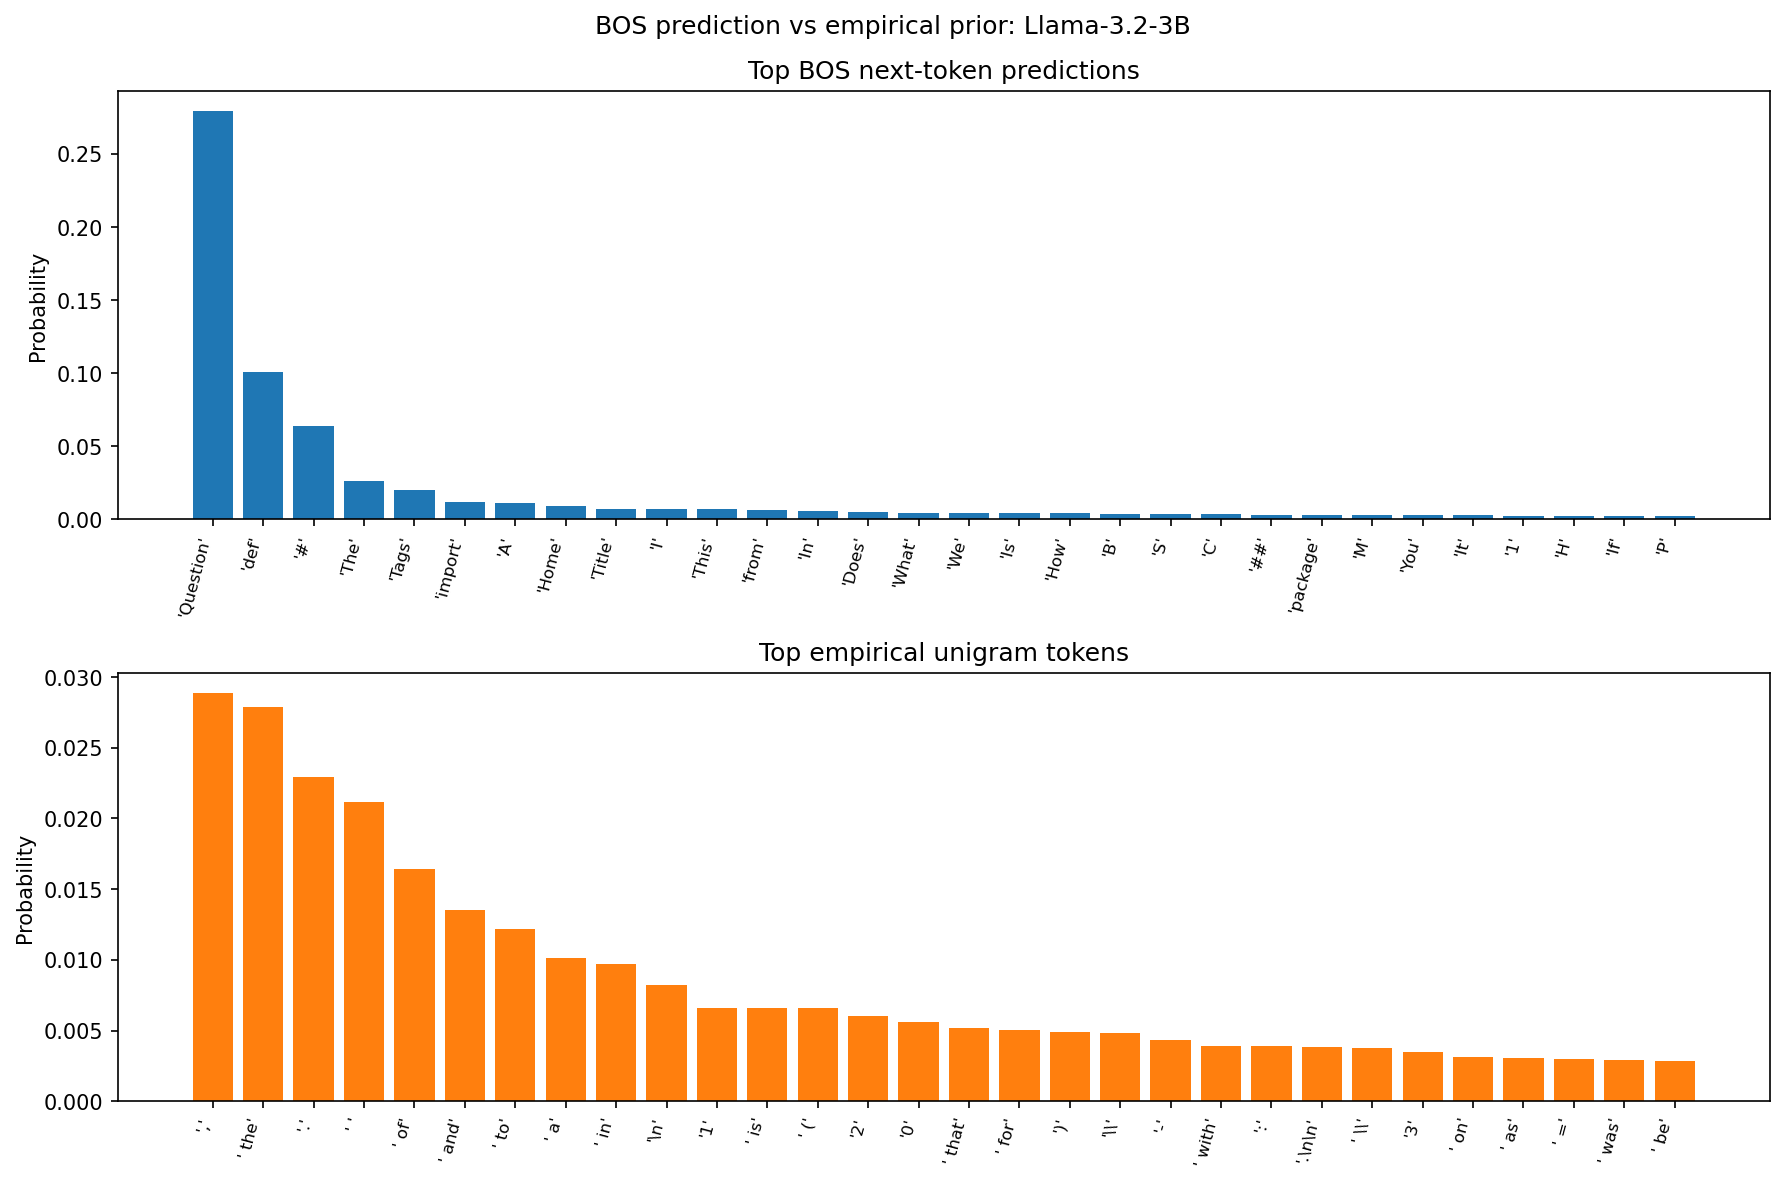

In [7]:
# Compare the model's start-of-sequence prediction to the empirical unigram prior.
top_k = 30
bos_id = tokenizer.bos_token_id
if bos_id is None:
    print("Tokenizer has no bos_token_id; skipping BOS next-token diagnostic.")
else:
    bos_input_ids = torch.tensor([[bos_id]], device=device, dtype=torch.long)
    with torch.no_grad():
        bos_logits = model(bos_input_ids).logits[0, -1].float().cpu().numpy()

    bos_probs = np.exp(bos_logits - bos_logits.max())
    bos_probs = bos_probs / bos_probs.sum()

    bos_top_ids = np.argsort(bos_probs)[-top_k:][::-1]
    prior_top_ids = np.argsort(p_zipf)[-top_k:][::-1]

    bos_top_tokens = [tokenizer.decode([int(tok_id)]) for tok_id in bos_top_ids]
    prior_top_tokens = [tokenizer.decode([int(tok_id)]) for tok_id in prior_top_ids]

    print("Top BOS next-token predictions:")
    for rank, (tok_id, tok, prob) in enumerate(zip(bos_top_ids, bos_top_tokens, bos_probs[bos_top_ids]), start=1):
        print(f"{rank:2d}. id={int(tok_id):6d} token={tok!r:20s} p={prob:.4e}")

    print("\nTop empirical p_zipf tokens:")
    for rank, (tok_id, tok, prob) in enumerate(zip(prior_top_ids, prior_top_tokens, p_zipf[prior_top_ids]), start=1):
        print(f"{rank:2d}. id={int(tok_id):6d} token={tok!r:20s} p={prob:.4e}")

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), dpi=150)

    x = np.arange(top_k)
    axes[0].bar(x, bos_probs[bos_top_ids], color="C0")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels([repr(tok) for tok in bos_top_tokens], rotation=75, ha="right", fontsize=8)
    axes[0].set_ylabel("Probability")
    axes[0].set_title("Top BOS next-token predictions")

    axes[1].bar(x, p_zipf[prior_top_ids], color="C1")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels([repr(tok) for tok in prior_top_tokens], rotation=75, ha="right", fontsize=8)
    axes[1].set_ylabel("Probability")
    axes[1].set_title("Top empirical unigram tokens")

    fig.suptitle(f"BOS prediction vs empirical prior: {model_name.split('/')[-1]}")
    fig.tight_layout()
    plt.show()


In [8]:
proj = embeddings_PCA[0]
pc_basis = basis_vectors_PCA[0]


### Three options for d_tilde
# 1. Frequency dipole. If p_zipf is empirical, exclude unobserved tokens
# before centering frequencies so zero means "unknown", not "known absent".
frequency_info_mask = p_zipf > 0
if not np.any(frequency_info_mask):
    raise ValueError("No tokens have positive frequency information.")

if dipole_method == "optimal_prior":
    optimal_prior_result = utils.frequency_dipole(
        w_out_np,
        p_zipf,
        method="optimal_prior",
        exclude_zeros=True,
    )
    d_tilde = optimal_prior_result["d_star"]
    d_zipf = optimal_prior_result
    Z_zipf = optimal_prior_result["beta_star"]
    print(
        f"Optimal-prior dipole uses {optimal_prior_result['n_tokens']:,}/{len(p_zipf):,} tokens; "
        f"beta={optimal_prior_result['beta_star']:.4g}, "
        f"R2={optimal_prior_result['r2']:.4f}, "
        f"cos(d*, d_tilde)={optimal_prior_result['cos_d_star_d_tilde']:.4f}."
    )
else:
    frequency_weights = p_zipf[frequency_info_mask]
    if log_frequency:
        frequency_weights = np.log(frequency_weights)

    d_tilde, d_zipf, Z_zipf = utils.frequency_dipole(
        w_out_np[frequency_info_mask],
        frequency_weights,
    )
    print(
        f"Frequency dipole uses {frequency_info_mask.sum():,}/{len(frequency_info_mask):,} "
        f"tokens with positive frequency information "
        f"({'log frequency' if log_frequency else 'frequency'} weights)."
    )

# 2. First PCA direction
# d_tilde = pc_basis[:, 0]

# 3. BOS hidden-state direction (active)
# bos_id = tokenizer.bos_token_id
# if bos_id is None:
#     raise ValueError("Tokenizer has no bos_token_id.")
# with torch.no_grad():
#     bos_outputs = forward_backbone(torch.tensor([[bos_id]], device=device, dtype=torch.long))
# d_tilde = utils.unit_vector(bos_outputs.last_hidden_state[0, -1].float().cpu().numpy())



Optimal-prior dipole uses 89,780/128,256 tokens; beta=36.44, R2=0.8729, cos(d*, d_tilde)=0.3030.


In [9]:
# Compare how well three candidate directions explain log-frequency in the loaded model unembedding.
dipole_diagnostics = dipole_utils.frequency_direction_diagnostics(w_out_np, p_zipf)
r2_df = dipole_diagnostics["table"]
display(r2_df)

print(f"n_tokens = {dipole_diagnostics['n_tokens']:,}/{len(p_zipf):,}")
print(f"ridge_lambda = {dipole_diagnostics['ridge_lambda']:.4g}")
print(
    "cos(d*, d_log_tilde) = "
    f"{np.dot(dipole_diagnostics['d_star'], dipole_diagnostics['d_log_tilde']):.4f}"
)
print(
    "cos(d*, d_tilde) = "
    f"{np.dot(dipole_diagnostics['d_star'], dipole_diagnostics['d_tilde']):.4f}"
)


,direction,R2,beta,residual_R2,residual_beta,total_R2_after_residual
0,d*,0.872943,36.442137,4.099140e-09,0.001409,0.872943
1,d_log_tilde,0.684545,10.967316,4.683324e-01,26.391144,0.832283
2,d_tilde,0.667082,11.203283,6.182623e-01,34.602531,0.872913


n_tokens = 89,780/128,256
ridge_lambda = 0.003585
cos(d*, d_log_tilde) = 0.3838
cos(d*, d_tilde) = 0.3030


Figure 1. Direction of prior emerges in unembedding.

(A) Top-2 principal component visualization of the Llama-3.2-3B unembedding.
Tokens are spatially graded when colored by frequency (cool→warm = rare→common).
Punctuations such as comma and period are the most frequent, followed by articles.
The black arrow marks the direction of prior $\boldsymbol{d}_{\mathrm{prior}}$, which points in the steepest direction of increasing frequency.

(B) Next-token prediction progressively aligns with $\boldsymbol{d}_{\mathrm{prior}}$ as context becomes vague.
All prompts share the fixed format "[context], we can find the …" and differ only in the spatial qualifier, ordered from most informative (In the Louvre) to most generic (In this world). For each prompt, $\boldsymbol{y}_{\mathrm{output}}$ is the last-token pre-softmax latent that is multiplied by the unembedding to produce the next-token logits. The prior reliance coefficient, $\cos(\boldsymbol{d}_{\mathrm{prior}}, \boldsymbol{y}_{\mathrm{output}}) \in [-1,1]$ grows as the context becomes less informative and the model falls back on the prior. Geometry is schematic (arrow lengths not to scale); positions encode cosine similarity up to affine transform; labels show true values computed from Llama-3.2-3B.



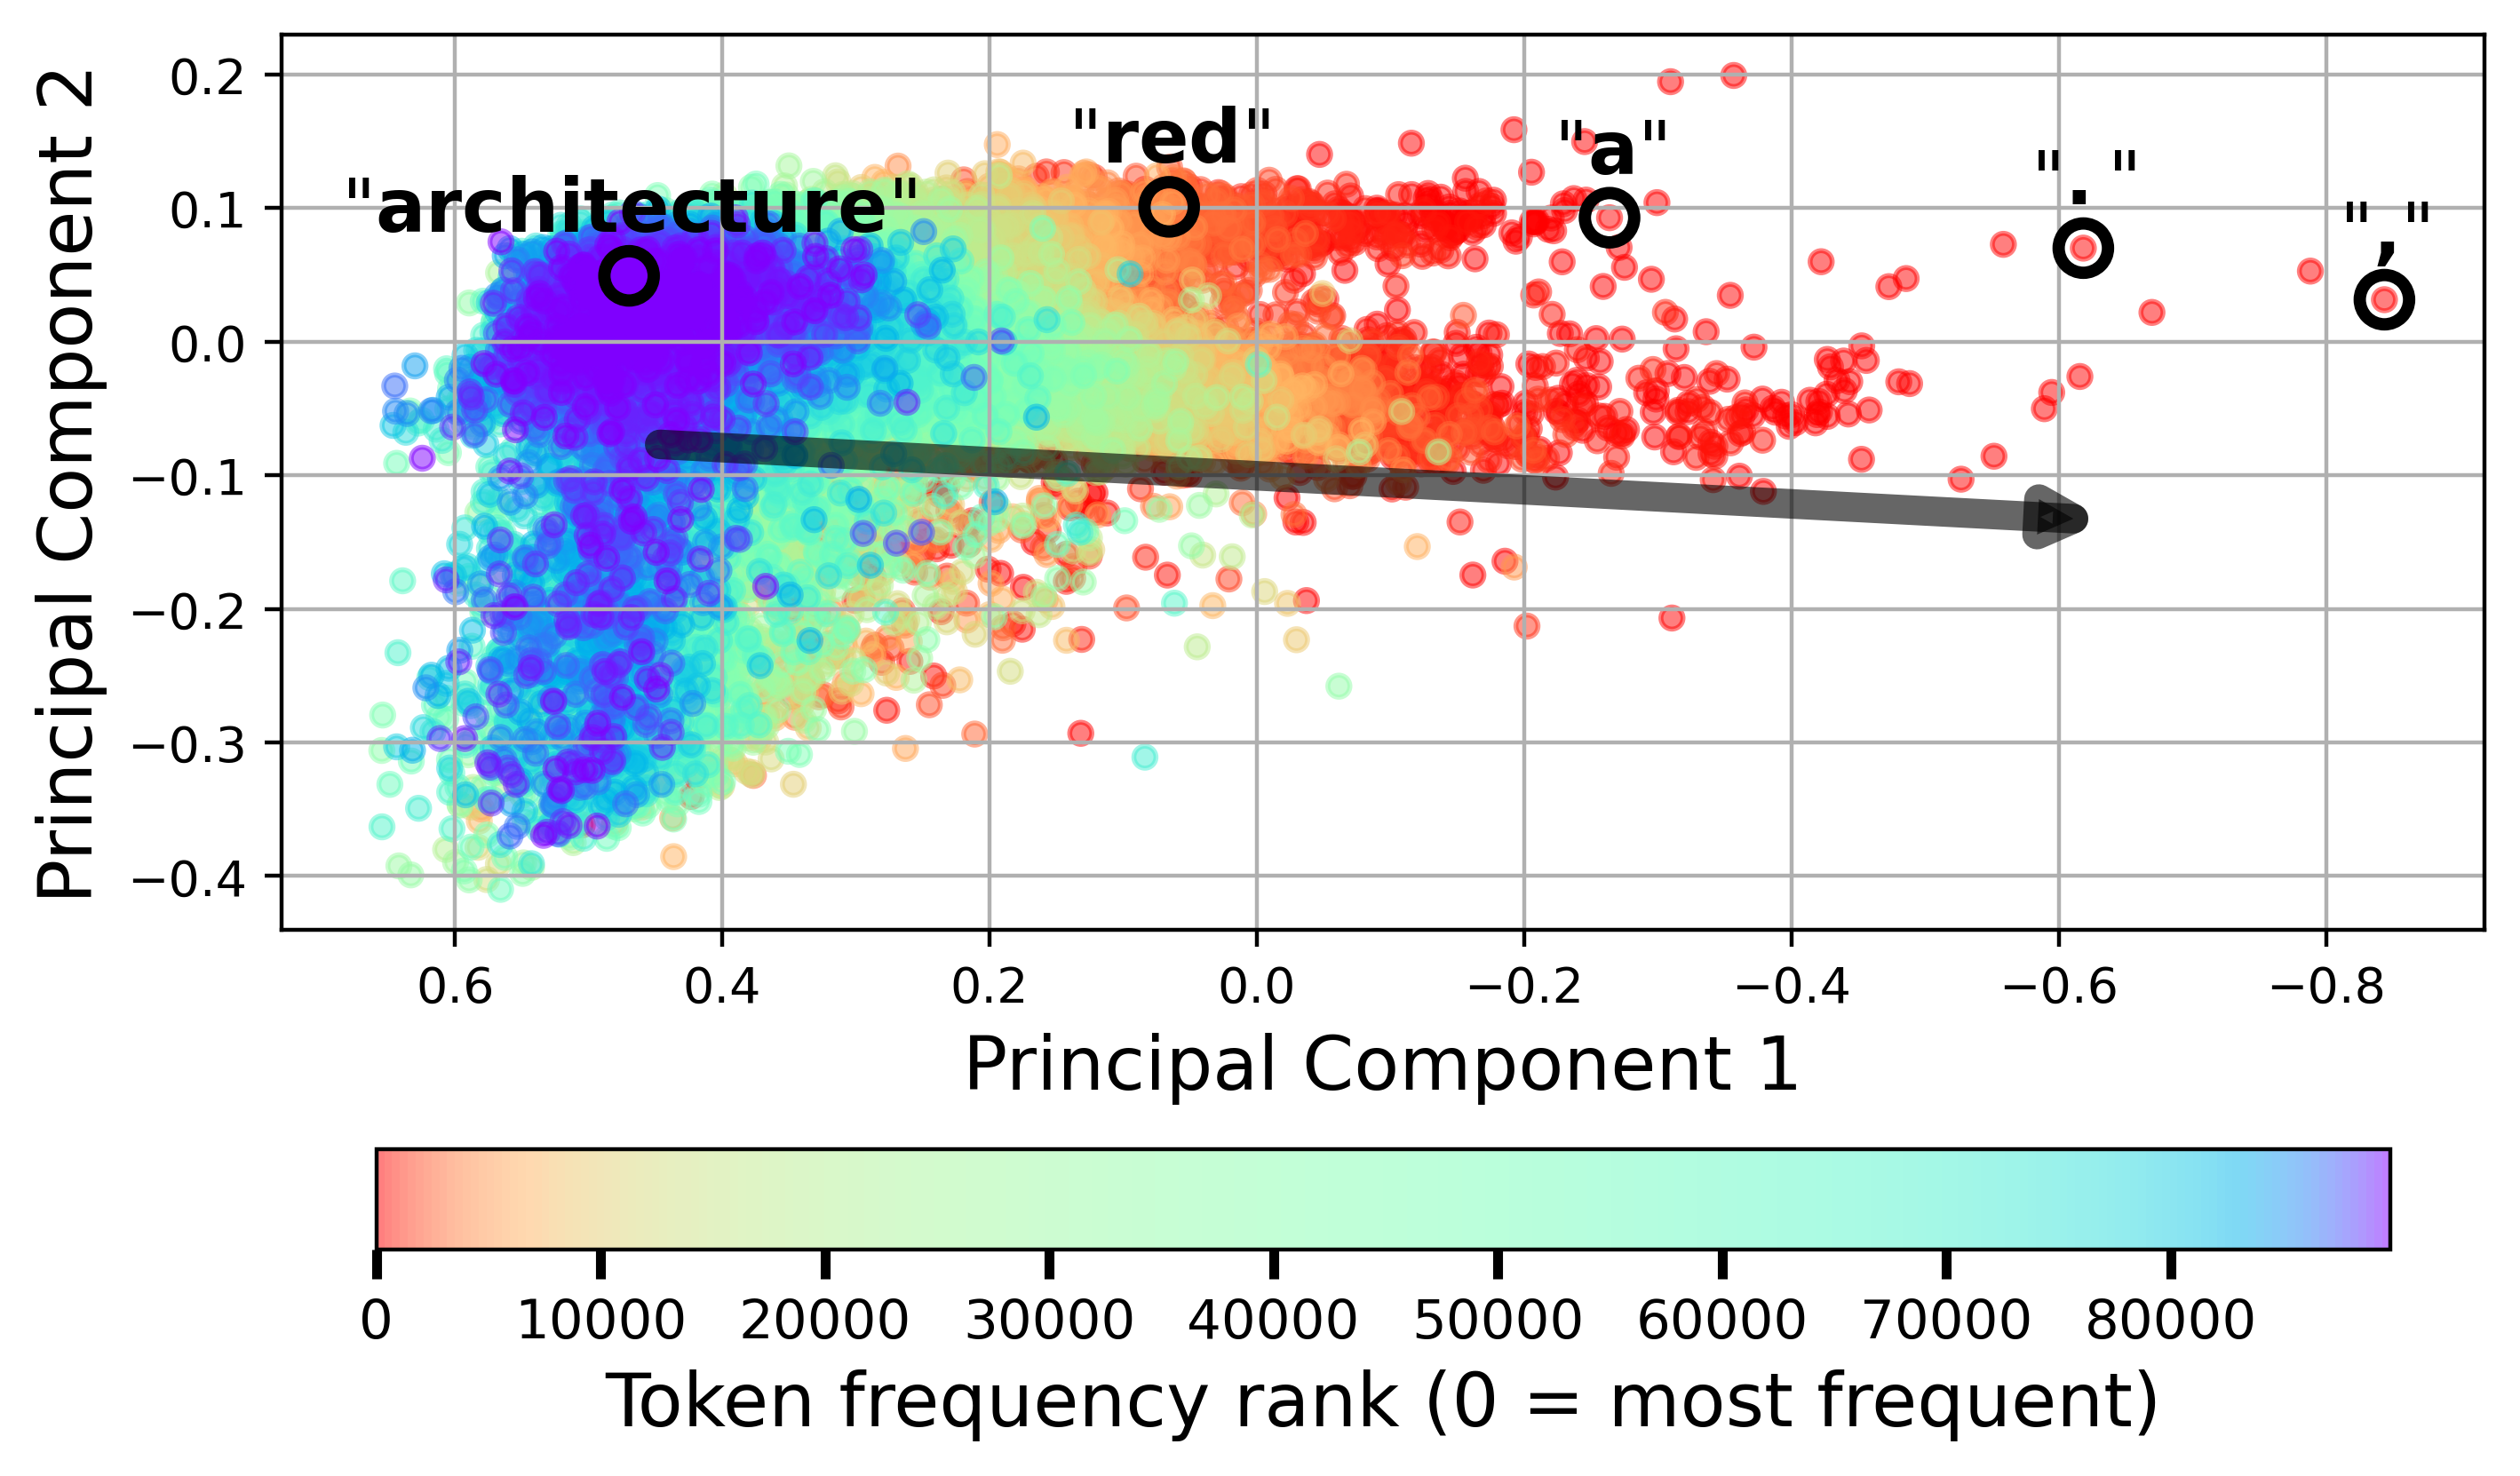

In [10]:
ax1 = 0
ax2 = 1
flip_x = True
# Restrict the cloud to tokens whose empirical Pile frequency we actually measured.
freq_mask = p_zipf > 0
freq_indices = np.where(freq_mask)[0]
proj_freq = proj[freq_mask]
p_freq = p_zipf[freq_mask]

# Color by frequency rank (0 = most frequent) so colors spread evenly across the
# heavy-tailed distribution instead of saturating at the few high-frequency tokens.
order = np.argsort(p_freq)[::-1]
freq_rank = np.empty(p_freq.shape[0], dtype=np.int64)
freq_rank[order] = np.arange(p_freq.shape[0])

# Global token id -> frequency rank so highlighted tokens share the cloud colormap.
rank_by_token = np.full(proj.shape[0], -1, dtype=np.int64)
rank_by_token[freq_indices] = freq_rank

# Draw most frequent first (bottom) and least frequent last (top).
proj_freq = proj_freq[order]
freq_rank = freq_rank[order]

d_proj = d_tilde @ pc_basis
d_xy = np.array([d_proj[ax1], d_proj[ax2]])
d_len = np.linalg.norm(d_xy)

tag_tokens = []
# tag_tokens = ["the", "blue", "red", "white", "man", "a", ",", ".", 'groupon', "1", "0"]
tag_tokens = ["a", ",", ".",'architecture' , 'red']
# tag_tokens = ["Paris", "Europe"]

tag_token_ids = [tokenizer.convert_tokens_to_ids(tok) for tok in tag_tokens]
highlight_proj = proj[tag_token_ids]
highlight_ranks = rank_by_token[tag_token_ids]

import matplotlib as mpl
# Tangent-warped rainbow_r: steep at the ends / flat in the middle, so the red and
# purple ends occupy less of the range and the middle is stretched, smoothing the
# red->orange and green->purple transitions.
_tan_k = 2.7  # 0 -> linear; larger -> shorter ends / longer middle (must be < pi)
_p = np.linspace(0.0, 1.0, 256)
_warp = np.clip(0.5 + 0.5 * np.tan(_tan_k * (_p - 0.5)) / np.tan(_tan_k / 2), 0.0, 1.0)
freq_cmap = mpl.colors.ListedColormap(plt.get_cmap("rainbow_r")(_warp))

fig, ax = plt.subplots(figsize=(8, 8), dpi=400)

sc = ax.scatter(
    proj_freq[:, ax1], proj_freq[:, ax2],
    s=20, marker="o",
    c=freq_rank,
    cmap=freq_cmap,
    alpha=0.5,
)
cbar = fig.colorbar(
    sc,
    ax=ax,
    orientation="horizontal",
    location="bottom",
    pad=0.1,
    fraction=0.046,
    label="Token frequency rank (0 = most frequent)",
)
# Bolden colorbar label and ticks
cbar.set_label("Token frequency rank (0 = most frequent)", fontsize=15)
cbar.ax.tick_params(labelsize=11, width=2, length=6)
# Rare (purple) on the left and frequent (red) on the right, matching the
# flipped PC1 axis above and the purple-to-red ordering of panel (b).
cbar.ax.invert_xaxis()
# for label in cbar.ax.get_xticklabels():
    # label.set_fontweight("bold")

# Highlighted tokens are drawn as black dots; quotes on the label mark them as words.
for token, coord, rank in zip(tag_tokens, highlight_proj, highlight_ranks):
    ax.scatter(coord[ax1], coord[ax2], s=100, facecolors='none', edgecolors="k", marker='o', zorder=5, alpha=1, linewidths=2.5)
    txt = ax.annotate(
        rf'"$\mathbf{{{token}}}$"', (coord[ax1], coord[ax2]),
        textcoords="offset points", xytext=(0, 6),
        fontsize=15, zorder=6, ha="center", va="bottom"
    )
    txt.set_clip_on(True)

# Frequency dipole arrow: length = 2/3 of the figure width, centered on the plot
# (it does not originate at the origin).
if d_len > 0:
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    cx = 0.5 * (xlim[0] + xlim[1])
    cy = 0.5 * (ylim[0] + ylim[1])
    arrow_len = (2.0 / 3.0) * (xlim[1] - xlim[0])
    vec = d_xy / d_len * arrow_len
    start = (cx - 0.5 * vec[0], cy - 0.5 * vec[1])
    end = (cx + 0.5 * vec[0], cy + 0.5 * vec[1])
    ax.annotate(
        "", xy=end, xytext=start,
        arrowprops=dict(arrowstyle="-|>", color="black", lw=6, mutation_scale=18, alpha = 0.6),
        zorder=7,
    )
    # Put the label in the middle of the arrow and vertically below the arrow.
    mid = ((start[0] + end[0]) / 2, (start[1] + end[1]) / 2)
    # ax.annotate(
    #     r"$\boldsymbol{d}_\text{prior}$", mid,
    #     textcoords="offset points", xytext=(0, -10),  # <-- negative value for below
    #     fontsize=20, color="black", fontweight="bold", zorder=8,
    #     ha="center", va="top"  # <-- 'va' is 'top' to anchor the top of the label at the offset
    # )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

ax.set_xlabel(f"Principal Component {ax1+1}", fontsize=15)
ax.set_ylabel(f"Principal Component {ax2+1}", fontsize=15)
# ax.set_title(f"Output-embedding PCA colored by empirical frequency ({int(freq_mask.sum()):,} tokens)")
ax.grid(True)
ax.set_aspect("equal", adjustable="box")
if flip_x:
    ax.invert_xaxis()
# plt.setp(ax.get_xticklabels(), fontweight="bold")
# plt.setp(ax.get_yticklabels(), fontweight="bold")

from pathlib import Path
export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
# fig.savefig(export_dir / "fig1_panelA_pca.pdf", bbox_inches="tight")
fig.savefig(export_dir / "fig1_panelA_pca.png", bbox_inches="tight")

plt.show()



### Panel b

In [11]:
sentence_list = [
    "In the Louvre, we can find the",
    "In Paris, we can find the",
    "In France, we can find the",
    "In Europe, we can find the",
    "On Earth, we can find the",
    "In this world, we can find the",]

# sentence_list = [
#     "The Louvre has",
#     "Paris has",
#     "France has",
#     "Europe has",
#     "The Earth has",
#     "The world has"]

In the Louvre     lambda = <d_hat_prior, y> / beta_star = 0.469
In Paris          lambda = <d_hat_prior, y> / beta_star = 0.523
In France         lambda = <d_hat_prior, y> / beta_star = 0.568
In Europe         lambda = <d_hat_prior, y> / beta_star = 0.596
On Earth          lambda = <d_hat_prior, y> / beta_star = 0.666
In this world     lambda = <d_hat_prior, y> / beta_star = 0.717


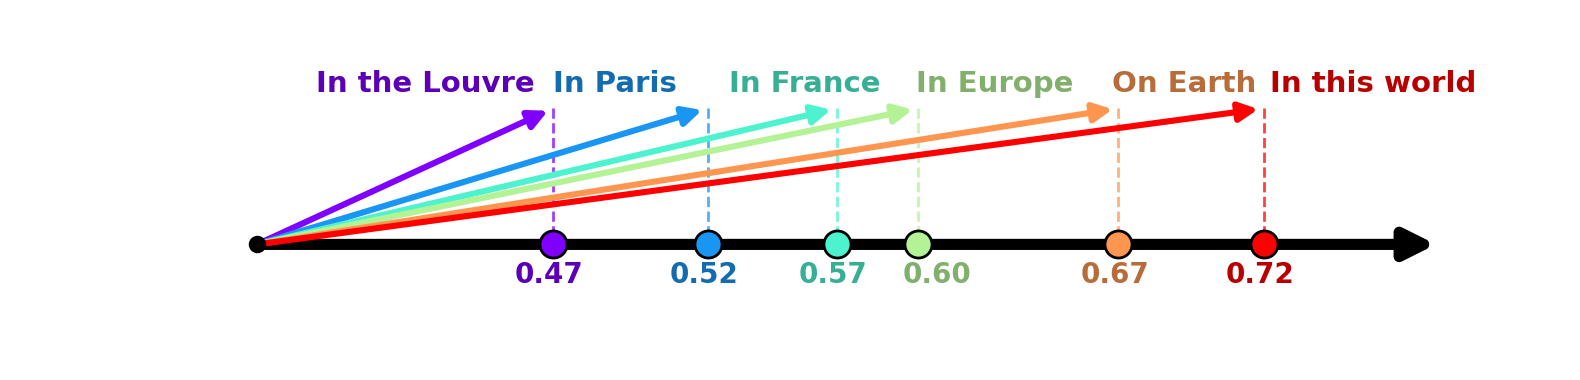

In [12]:
# Figure 1, Panel B: schematic projection diagram (prior loading factor).
# Scientific message: as the context becomes less specific / less certain, the
# predicted next-state vector y carries more of the prior, measured by the
# prior loading factor lambda = <d_hat_prior, y> / beta_star -- the exponent
# applied to the unigram prior in p_model(t) ∝ p_prior(t)^lambda * exp(<w_t, y_perp>).
# lambda = 1 means the prior at full native strength; lambda = 0 means none.
# The values are computed here from the loaded model (NOT hard-coded).
# Geometry is schematic: horizontal endpoint positions are affine in the true
# loading factor (ordering + relative spacing preserved) but angles are compressed so the
# near-orthogonal vectors remain legible. Styled to match Panel A (8x8, dpi 200,
# rainbow color family, thick charcoal d_prior arrow, same math typography).
# Note: HF last_hidden_state is already post-final-norm; do NOT re-apply norm.
from importlib import reload
reload(dipole_utils)

d_tilde_unit = utils.unit_vector(d_tilde)

try:
    sentence_groups = sentence_list_master
except NameError:
    sentence_groups = sentence_list
if sentence_groups and isinstance(sentence_groups[0], str):
    sentence_groups = [sentence_groups]
prompts = [sentence for group in sentence_groups for sentence in group]

# --- Measured prior loading factor lambda = <d_hat_prior, y> / beta_star ---
# beta_star = ||d_prior|| from the optimal-prior fit (Z_zipf in this notebook),
# so lambda is the raw projection of y onto d_hat, in units of beta_star.
beta_star = float(Z_zipf)
lambdas = []
for sentence in prompts:
    y = dipole_utils.last_hidden_vector(sentence, tokenizer, device, forward_backbone)
    lambdas.append(float(np.dot(y, d_tilde_unit)) / beta_star)
lambdas = np.array(lambdas)

# Show the shared suffix once; label vectors only by their varying context phrase.
suffix = ", we can find the"
contexts = [p.split(suffix)[0].strip() if suffix in p else p for p in prompts]
for ctx, lam in zip(contexts, lambdas):
    print(f"{ctx:16s}  lambda = <d_hat_prior, y> / beta_star = {lam:.3f}")

n = len(prompts)
# Panel A frequency-rank palette: cool (purple) -> warm (red), left -> right.
colors = plt.get_cmap("rainbow")(np.linspace(0.0, 1.0, n))
# Darker variants for text so pale hues (cyan/green/gold) stay legible.
dark_colors = colors.copy()
dark_colors[:, :3] *= 0.72

# ---- Schematic layout (axes-fraction coordinates) ----
x0, y0 = 0.14, 0.34          # common origin on the d_prior axis
axis_end = 0.94              # d_prior arrow tip
x_lo, x_hi = 0.34, 0.82      # horizontal range of projected endpoints
H = 0.74                     # common height of the prediction-vector tips

lam_min, lam_max = float(lambdas.min()), float(lambdas.max())
if lam_max > lam_min:
    x_proj = x_lo + (lambdas - lam_min) / (lam_max - lam_min) * (x_hi - x_lo)
else:
    x_proj = np.full(n, 0.5 * (x_lo + x_hi))

fig, ax = plt.subplots(figsize=(8, 2), dpi=200)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(0.0, 1.0)
ax.axis("off")


# (1) d_prior axis: thick charcoal arrow pointing right.
ax.annotate("", xy=(axis_end, y0), xytext=(x0, y0),
            arrowprops=dict(arrowstyle="-|>", color='black', lw=4, mutation_scale=22), zorder=3)
# ax.text(0.5 * (x0 + axis_end), y0 - 0.13, r"$\boldsymbol{d}_{\mathrm{prior}}$",
#         color='black', fontsize=20, fontweight="bold", ha="center", va="center")
ax.scatter([x0], [y0], color="black", s=28, zorder=6)  # common origin

# (2) six prediction vectors, dashed perpendiculars, solid projected markers.
for i in range(n):
    xt = x_proj[i]
    ax.annotate("", xy=(xt, H), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=colors[i], lw=2.2, mutation_scale=14), zorder=4)
    ax.plot([xt, xt], [H, y0], color=colors[i], lw=1.0, ls="--", alpha=0.75, zorder=2)
    ax.scatter([xt], [y0], color=colors[i], edgecolors="k", s=95, lw=1.0, zorder=6)

# Keep labels/numbers close to their true projection x, nudging apart only the
# columns that would collide so each still fits on a single line.
def spread(pos, min_gap, lo=0.03, hi=0.99):
    x = np.asarray(pos, float)
    order = np.argsort(x)
    xs = x[order].copy()
    for i in range(1, len(xs)):
        if xs[i] - xs[i - 1] < min_gap:
            xs[i] = xs[i - 1] + min_gap
    xs += x.mean() - xs.mean()               # recenter on original mean
    xs = np.clip(xs, lo, hi)
    for i in range(1, len(xs)):              # re-enforce gaps after clipping
        if xs[i] - xs[i - 1] < min_gap:
            xs[i] = xs[i - 1] + min_gap
    out = np.empty_like(xs)
    out[order] = xs
    return out

x_num = spread(x_proj, 0.070)   # loading-factor values (short) hug the markers
x_lab = spread(x_proj, 0.128)   # context labels (longer) nudged apart minimally

# (3) loading-factor values on one line, close to each projection.
for i in range(n):
    ax.text(x_num[i], y0 - 0.05, f"{lambdas[i]:.2f}", color=dark_colors[i],
            fontsize=10, fontweight="bold", ha="center", va="top", zorder=7)

# (4) context labels on one line near the vector tips, colored to match
#     (no leader lines; spatial correspondence is enough).
for i in range(n):
    ax.text(x_lab[i], H + 0.03, contexts[i], color=dark_colors[i], fontsize=10.5,
            fontweight="bold", ha="center", va="bottom", zorder=7)

# # (5) shared prompt template once at the top; [context] emphasized in bold.
# ax.text(0.5, 0.965, r"Prompt:  $\mathbf{[context]}$, we can find the …",
#         fontsize=14, ha="center", va="center", zorder=7)


j = int(np.argmax(lambdas))
arr_y = 0.15

# ax.text(x_proj[j], arr_y + 0.03,
#         r"$\lambda = \langle \hat{\boldsymbol{d}}_{\mathrm{prior}},\, y_{\mathrm{output}}\rangle / \beta_\star$",
#         color='black', fontsize=12, ha="center", va="bottom", zorder=7)

fig.tight_layout()

# Save vector copies (editable PDF + SVG) to plot_export/.
from pathlib import Path
export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(export_dir / "fig1_panelB_Louvre_loading.pdf", bbox_inches="tight")

plt.show()

In the Louvre     cos(d_prior, y) = 0.199
In Paris          cos(d_prior, y) = 0.226
In France         cos(d_prior, y) = 0.249
In Europe         cos(d_prior, y) = 0.264
On Earth          cos(d_prior, y) = 0.295
In this world     cos(d_prior, y) = 0.310


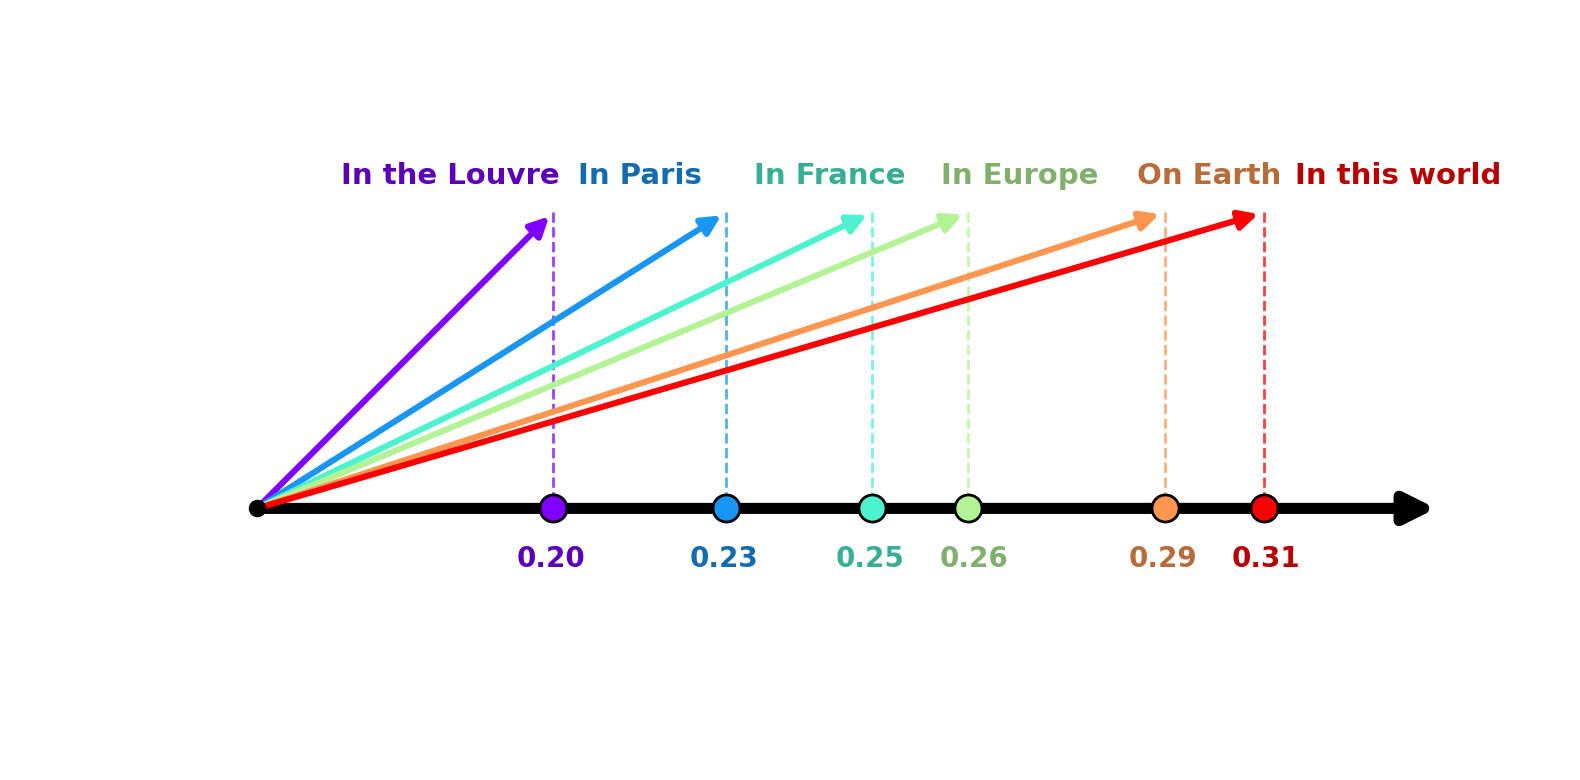

In [ ]:
# # Figure 1, Panel B: schematic projection diagram.
# # Scientific message: as the context becomes less specific / less certain, the
# # predicted next-state vector y aligns more with the direction of prior,
# # d_prior, measured by cos(d_prior, y). The cosine values are computed
# # here from the loaded model (NOT hard-coded).
# # Geometry is schematic: horizontal endpoint positions are affine in the true
# # cosine (ordering + relative spacing preserved) but angles are compressed so the
# # near-orthogonal vectors remain legible. Styled to match Panel A (8x8, dpi 200,
# # rainbow color family, thick charcoal d_prior arrow, same math typography).
# # Note: HF last_hidden_state is already post-final-norm; do NOT re-apply norm.
# from importlib import reload
# reload(dipole_utils)

# d_tilde_unit = utils.unit_vector(d_tilde)

# try:
#     sentence_groups = sentence_list_master
# except NameError:
#     sentence_groups = sentence_list
# if sentence_groups and isinstance(sentence_groups[0], str):
#     sentence_groups = [sentence_groups]
# prompts = [sentence for group in sentence_groups for sentence in group]

# # --- Measured alignment cos(d_prior, y), computed from the model ---
# alphas = []
# for sentence in prompts:
#     y = dipole_utils.last_hidden_vector(sentence, tokenizer, device, forward_backbone)
#     alphas.append(float(np.dot(utils.unit_vector(y), d_tilde_unit)))
# alphas = np.array(alphas)

# # Show the shared suffix once; label vectors only by their varying context phrase.
# suffix = ", we can find the"
# contexts = [p.split(suffix)[0].strip() if suffix in p else p for p in prompts]
# for ctx, a in zip(contexts, alphas):
#     print(f"{ctx:16s}  cos(d_prior, y) = {a:.3f}")

# n = len(prompts)
# # Panel A frequency-rank palette: cool (purple) -> warm (red), left -> right.
# colors = plt.get_cmap("rainbow")(np.linspace(0.0, 1.0, n))
# # Darker variants for text so pale hues (cyan/green/gold) stay legible.
# dark_colors = colors.copy()
# dark_colors[:, :3] *= 0.72

# # ---- Schematic layout (axes-fraction coordinates) ----
# x0, y0 = 0.14, 0.34          # common origin on the d_prior axis
# axis_end = 0.94              # d_prior arrow tip
# x_lo, x_hi = 0.34, 0.82      # horizontal range of projected endpoints
# H = 0.74                     # common height of the prediction-vector tips

# a_min, a_max = float(alphas.min()), float(alphas.max())
# if a_max > a_min:
#     x_proj = x_lo + (alphas - a_min) / (a_max - a_min) * (x_hi - x_lo)
# else:
#     x_proj = np.full(n, 0.5 * (x_lo + x_hi))

# fig, ax = plt.subplots(figsize=(8, 4), dpi=200)
# ax.set_xlim(-0.02, 1.02)
# ax.set_ylim(0.0, 1.0)
# ax.axis("off")


# # (1) d_prior axis: thick charcoal arrow pointing right.
# ax.annotate("", xy=(axis_end, y0), xytext=(x0, y0),
#             arrowprops=dict(arrowstyle="-|>", color='black', lw=4, mutation_scale=22), zorder=3)
# # ax.text(0.5 * (x0 + axis_end), y0 - 0.13, r"$\boldsymbol{d}_{\mathrm{prior}}$",
# #         color='black', fontsize=20, fontweight="bold", ha="center", va="center")
# ax.scatter([x0], [y0], color="black", s=28, zorder=6)  # common origin

# # (2) six prediction vectors, dashed perpendiculars, solid projected markers.
# for i in range(n):
#     xt = x_proj[i]
#     ax.annotate("", xy=(xt, H), xytext=(x0, y0),
#                 arrowprops=dict(arrowstyle="-|>", color=colors[i], lw=2.2, mutation_scale=14), zorder=4)
#     ax.plot([xt, xt], [H, y0], color=colors[i], lw=1.0, ls="--", alpha=0.75, zorder=2)
#     ax.scatter([xt], [y0], color=colors[i], edgecolors="k", s=95, lw=1.0, zorder=6)

# # Keep labels/numbers close to their true projection x, nudging apart only the
# # columns that would collide so each still fits on a single line.
# def spread(pos, min_gap, lo=0.03, hi=0.99):
#     x = np.asarray(pos, float)
#     order = np.argsort(x)
#     xs = x[order].copy()
#     for i in range(1, len(xs)):
#         if xs[i] - xs[i - 1] < min_gap:
#             xs[i] = xs[i - 1] + min_gap
#     xs += x.mean() - xs.mean()               # recenter on original mean
#     xs = np.clip(xs, lo, hi)
#     for i in range(1, len(xs)):              # re-enforce gaps after clipping
#         if xs[i] - xs[i - 1] < min_gap:
#             xs[i] = xs[i - 1] + min_gap
#     out = np.empty_like(xs)
#     out[order] = xs
#     return out

# x_num = spread(x_proj, 0.070)   # cosine values (short) hug the markers
# x_lab = spread(x_proj, 0.128)   # context labels (longer) nudged apart minimally

# # (3) cosine values (3 decimals) on one line, close to each projection.
# for i in range(n):
#     ax.text(x_num[i], y0 - 0.05, f"{alphas[i]:.2f}", color=dark_colors[i],
#             fontsize=10, fontweight="bold", ha="center", va="top", zorder=7)

# # (4) context labels on one line near the vector tips, colored to match
# #     (no leader lines; spatial correspondence is enough).
# for i in range(n):
#     ax.text(x_lab[i], H + 0.03, contexts[i], color=dark_colors[i], fontsize=10.5,
#             fontweight="bold", ha="center", va="bottom", zorder=7)

# # # (5) shared prompt template once at the top; [context] emphasized in bold.
# # ax.text(0.5, 0.965, r"Prompt:  $\mathbf{[context]}$, we can find the …",
# #         fontsize=14, ha="center", va="center", zorder=7)


# j = int(np.argmax(alphas))
# arr_y = 0.15

# # ax.text(x_proj[j], arr_y + 0.03,
# #         r"$\cos(\boldsymbol{d}_{\mathrm{prior}},\, y_{\mathrm{output}})$",
# #         color='black', fontsize=12, ha="center", va="bottom", zorder=7)

# fig.tight_layout()

# # Save vector copies (editable PDF + SVG) to plot_export/.
# from pathlib import Path
# export_dir = Path("plot_export")
# export_dir.mkdir(parents=True, exist_ok=True)
# fig.savefig(export_dir / "fig1_panelB_Louvre.pdf", bbox_inches="tight")

# plt.show()

In the Louvre     cos(d_prior, y) = 0.199
In Paris          cos(d_prior, y) = 0.226
In France         cos(d_prior, y) = 0.249
In Europe         cos(d_prior, y) = 0.264
On Earth          cos(d_prior, y) = 0.295
In this world     cos(d_prior, y) = 0.310


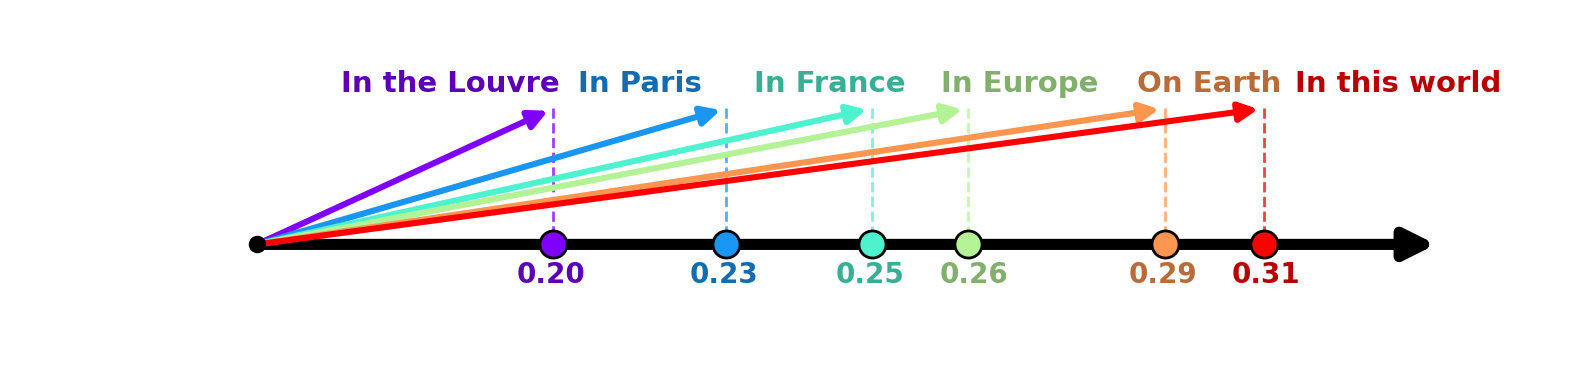

In [ ]:
# # Figure 1, Panel B: schematic projection diagram.
# # Scientific message: as the context becomes less specific / less certain, the
# # predicted next-state vector y aligns more with the direction of prior,
# # d_prior, measured by cos(d_prior, y). The cosine values are computed
# # here from the loaded model (NOT hard-coded).
# # Geometry is schematic: horizontal endpoint positions are affine in the true
# # cosine (ordering + relative spacing preserved) but angles are compressed so the
# # near-orthogonal vectors remain legible. Styled to match Panel A (8x8, dpi 200,
# # rainbow color family, thick charcoal d_prior arrow, same math typography).
# # Note: HF last_hidden_state is already post-final-norm; do NOT re-apply norm.
# from importlib import reload
# reload(dipole_utils)

# d_tilde_unit = utils.unit_vector(d_tilde)

# try:
#     sentence_groups = sentence_list_master
# except NameError:
#     sentence_groups = sentence_list
# if sentence_groups and isinstance(sentence_groups[0], str):
#     sentence_groups = [sentence_groups]
# prompts = [sentence for group in sentence_groups for sentence in group]

# # --- Measured alignment cos(d_prior, y), computed from the model ---
# alphas = []
# for sentence in prompts:
#     y = dipole_utils.last_hidden_vector(sentence, tokenizer, device, forward_backbone)
#     alphas.append(float(np.dot(utils.unit_vector(y), d_tilde_unit)))
# alphas = np.array(alphas)

# # Show the shared suffix once; label vectors only by their varying context phrase.
# suffix = ", we can find the"
# contexts = [p.split(suffix)[0].strip() if suffix in p else p for p in prompts]
# for ctx, a in zip(contexts, alphas):
#     print(f"{ctx:16s}  cos(d_prior, y) = {a:.3f}")

# n = len(prompts)
# # Panel A frequency-rank palette: cool (purple) -> warm (red), left -> right.
# colors = plt.get_cmap("rainbow")(np.linspace(0.0, 1.0, n))
# # Darker variants for text so pale hues (cyan/green/gold) stay legible.
# dark_colors = colors.copy()
# dark_colors[:, :3] *= 0.72

# # ---- Schematic layout (axes-fraction coordinates) ----
# x0, y0 = 0.14, 0.34          # common origin on the d_prior axis
# axis_end = 0.94              # d_prior arrow tip
# x_lo, x_hi = 0.34, 0.82      # horizontal range of projected endpoints
# H = 0.74                     # common height of the prediction-vector tips

# a_min, a_max = float(alphas.min()), float(alphas.max())
# if a_max > a_min:
#     x_proj = x_lo + (alphas - a_min) / (a_max - a_min) * (x_hi - x_lo)
# else:
#     x_proj = np.full(n, 0.5 * (x_lo + x_hi))

# fig, ax = plt.subplots(figsize=(8, 2), dpi=200)
# ax.set_xlim(-0.02, 1.02)
# ax.set_ylim(0.0, 1.0)
# ax.axis("off")


# # (1) d_prior axis: thick charcoal arrow pointing right.
# ax.annotate("", xy=(axis_end, y0), xytext=(x0, y0),
#             arrowprops=dict(arrowstyle="-|>", color='black', lw=4, mutation_scale=22), zorder=3)
# # ax.text(0.5 * (x0 + axis_end), y0 - 0.13, r"$\boldsymbol{d}_{\mathrm{prior}}$",
# #         color='black', fontsize=20, fontweight="bold", ha="center", va="center")
# ax.scatter([x0], [y0], color="black", s=28, zorder=6)  # common origin

# # (2) six prediction vectors, dashed perpendiculars, solid projected markers.
# for i in range(n):
#     xt = x_proj[i]
#     ax.annotate("", xy=(xt, H), xytext=(x0, y0),
#                 arrowprops=dict(arrowstyle="-|>", color=colors[i], lw=2.2, mutation_scale=14), zorder=4)
#     ax.plot([xt, xt], [H, y0], color=colors[i], lw=1.0, ls="--", alpha=0.75, zorder=2)
#     ax.scatter([xt], [y0], color=colors[i], edgecolors="k", s=95, lw=1.0, zorder=6)

# # Keep labels/numbers close to their true projection x, nudging apart only the
# # columns that would collide so each still fits on a single line.
# def spread(pos, min_gap, lo=0.03, hi=0.99):
#     x = np.asarray(pos, float)
#     order = np.argsort(x)
#     xs = x[order].copy()
#     for i in range(1, len(xs)):
#         if xs[i] - xs[i - 1] < min_gap:
#             xs[i] = xs[i - 1] + min_gap
#     xs += x.mean() - xs.mean()               # recenter on original mean
#     xs = np.clip(xs, lo, hi)
#     for i in range(1, len(xs)):              # re-enforce gaps after clipping
#         if xs[i] - xs[i - 1] < min_gap:
#             xs[i] = xs[i - 1] + min_gap
#     out = np.empty_like(xs)
#     out[order] = xs
#     return out

# x_num = spread(x_proj, 0.070)   # cosine values (short) hug the markers
# x_lab = spread(x_proj, 0.128)   # context labels (longer) nudged apart minimally

# # (3) cosine values (3 decimals) on one line, close to each projection.
# for i in range(n):
#     ax.text(x_num[i], y0 - 0.05, f"{alphas[i]:.2f}", color=dark_colors[i],
#             fontsize=10, fontweight="bold", ha="center", va="top", zorder=7)

# # (4) context labels on one line near the vector tips, colored to match
# #     (no leader lines; spatial correspondence is enough).
# for i in range(n):
#     ax.text(x_lab[i], H + 0.03, contexts[i], color=dark_colors[i], fontsize=10.5,
#             fontweight="bold", ha="center", va="bottom", zorder=7)

# # # (5) shared prompt template once at the top; [context] emphasized in bold.
# # ax.text(0.5, 0.965, r"Prompt:  $\mathbf{[context]}$, we can find the …",
# #         fontsize=14, ha="center", va="center", zorder=7)


# j = int(np.argmax(alphas))
# arr_y = 0.15

# # ax.text(x_proj[j], arr_y + 0.03,
# #         r"$\cos(\boldsymbol{d}_{\mathrm{prior}},\, y_{\mathrm{output}})$",
# #         color='black', fontsize=12, ha="center", va="bottom", zorder=7)

# fig.tight_layout()

# # Save vector copies (editable PDF + SVG) to plot_export/.
# from pathlib import Path
# export_dir = Path("plot_export")
# export_dir.mkdir(parents=True, exist_ok=True)
# fig.savefig(export_dir / "fig1_panelB_Louvre.pdf", bbox_inches="tight")

# plt.show()

In [15]:
# # Zipf plot: empirical token frequency vs frequency rank on log-log axes.
# freq_measured = p_zipf[p_zipf > 0]
# freq_sorted = np.sort(freq_measured)[::-1]
# rank = np.arange(1, freq_sorted.size + 1)

# fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
# ax.bar(rank, freq_sorted, width=1.0, align="edge", color="C0")

# # Reference Zipf slope -1 (frequency proportional to 1/rank) in log-log space.
# zipf_ref = freq_sorted[0] / rank
# ax.plot(rank, zipf_ref, color="k", ls="--", lw=1.5, label="slope $-1$ (Zipf)")
# ax.legend()

# ax.set_xscale("log")
# ax.set_yscale("log")
# ax.set_xlabel("Frequency rank (index)")
# ax.set_ylabel("Empirical token probability")
# ax.set_title(f"Empirical Pile token frequency (Zipf), {freq_sorted.size:,} tokens")
# ax.grid(True, which="both", alpha=0.3)
# plt.setp(ax.get_xticklabels(), fontweight="bold")
# plt.setp(ax.get_yticklabels(), fontweight="bold")
# plt.tight_layout()
# plt.show()

### Additional investigation

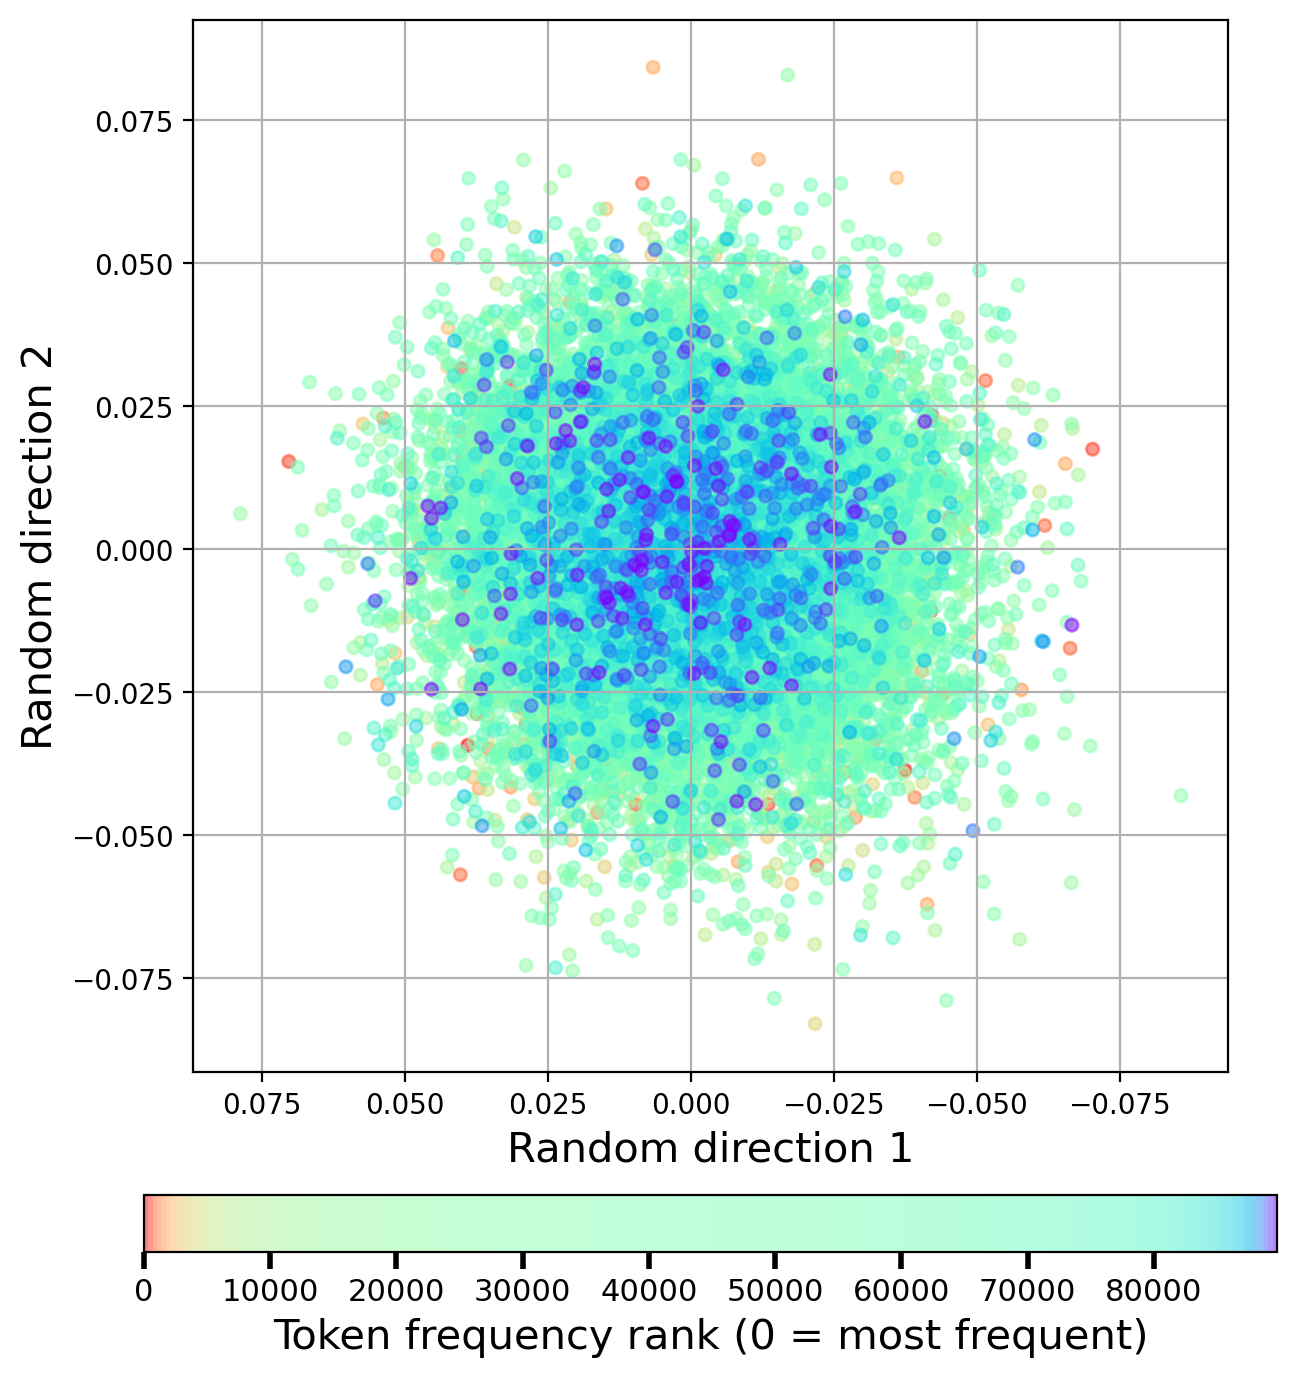

In [16]:
random_seed = 0
flip_x = True
subrate = 4
_tan_k = 3 # 0 -> linear; larger -> shorter ends / longer middle (must be < pi)
# Construct a deterministic random 2D plane in the output-embedding space.
# QR orthonormalization keeps the two plotted directions perpendicular and unit length.
rng = np.random.default_rng(random_seed)
random_directions, _ = np.linalg.qr(
    rng.standard_normal((w_out_np.shape[1], 2))
)
centered_embeddings = w_out_np - w_out_np.mean(axis=0, keepdims=True)
random_proj = centered_embeddings @ random_directions

# Restrict the cloud to tokens whose empirical Pile frequency we actually measured.
freq_mask = p_zipf > 0
freq_indices = np.where(freq_mask)[0]
proj_freq = random_proj[freq_mask]
p_freq = p_zipf[freq_mask]

# Color by frequency rank (0 = most frequent) so colors spread evenly across the
# heavy-tailed distribution instead of saturating at the few high-frequency tokens.
order = np.argsort(p_freq)[::-1]
freq_rank = np.empty(p_freq.shape[0], dtype=np.int64)
freq_rank[order] = np.arange(p_freq.shape[0])

# Global token id -> frequency rank so highlighted tokens share the cloud colormap.
rank_by_token = np.full(random_proj.shape[0], -1, dtype=np.int64)
rank_by_token[freq_indices] = freq_rank

# Draw most frequent first (bottom) and least frequent last (top), retaining
# every `subrate`-th frequency-ranked token to make the cloud sparser.
plot_indices = order[::subrate]
proj_freq = proj_freq[plot_indices]
freq_rank = freq_rank[plot_indices]

tag_tokens = []
# tag_tokens = ["the", "blue", "red", "white", "man", "a", ",", ".", 'groupon', "1", "0"]
# tag_tokens = ["a", ",", ".", 'architecture', 'red']
# tag_tokens = ["Paris", "Europe"]

tag_token_ids = [tokenizer.convert_tokens_to_ids(tok) for tok in tag_tokens]
highlight_proj = random_proj[tag_token_ids]
highlight_ranks = rank_by_token[tag_token_ids]

import matplotlib as mpl
# Tangent-warped rainbow_r: steep at the ends / flat in the middle, so the red and
# purple ends occupy less of the range and the middle is stretched, smoothing the
# red->orange and green->purple transitions.

_p = np.linspace(0.0, 1.0, 256)
_warp = np.clip(0.5 + 0.5 * np.tan(_tan_k * (_p - 0.5)) / np.tan(_tan_k / 2), 0.0, 1.0)
freq_cmap = mpl.colors.ListedColormap(plt.get_cmap("rainbow_r")(_warp))

fig, ax = plt.subplots(figsize=(8, 8), dpi=200)

sc = ax.scatter(
    proj_freq[:, 0], proj_freq[:, 1],
    s=20, marker="o",
    c=freq_rank,
    cmap=freq_cmap,
    alpha=0.5,
)
cbar = fig.colorbar(
    sc,
    ax=ax,
    orientation="horizontal",
    location="bottom",
    pad=0.1,
    fraction=0.046,
    label="Token frequency rank (0 = most frequent)",
)
# Bolden colorbar label and ticks
cbar.set_label("Token frequency rank (0 = most frequent)", fontsize=15)
cbar.ax.tick_params(labelsize=11, width=2, length=6)
# for label in cbar.ax.get_xticklabels():
    # label.set_fontweight("bold")

# Highlighted tokens are drawn as black dots; quotes on the label mark them as words.
for token, coord, rank in zip(tag_tokens, highlight_proj, highlight_ranks):
    ax.scatter(coord[0], coord[1], s=100, facecolors='none', edgecolors="k", marker='o', zorder=5, alpha=1, linewidths=2.5)
    txt = ax.annotate(
        rf'"$\mathbf{{{token}}}$"', (coord[0], coord[1]),
        textcoords="offset points", xytext=(0, 6),
        fontsize=15, zorder=6, ha="center", va="bottom"
    )
    txt.set_clip_on(True)


ax.set_xlabel("Random direction 1", fontsize=15)
ax.set_ylabel("Random direction 2", fontsize=15)
# ax.set_title(f"Random projection of output embeddings ({int(freq_mask.sum()):,} tokens)")
ax.grid(True)
ax.set_aspect("equal", adjustable="box")
if flip_x:
    ax.invert_xaxis()
# plt.setp(ax.get_xticklabels(), fontweight="bold")
# plt.setp(ax.get_yticklabels(), fontweight="bold")

from pathlib import Path
export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(export_dir / "fig1_panelA_random_projection.pdf", bbox_inches="tight")

plt.show()



### Results for Appendix

fig saved at plot_export/appdx_pca_multimodel.pdf


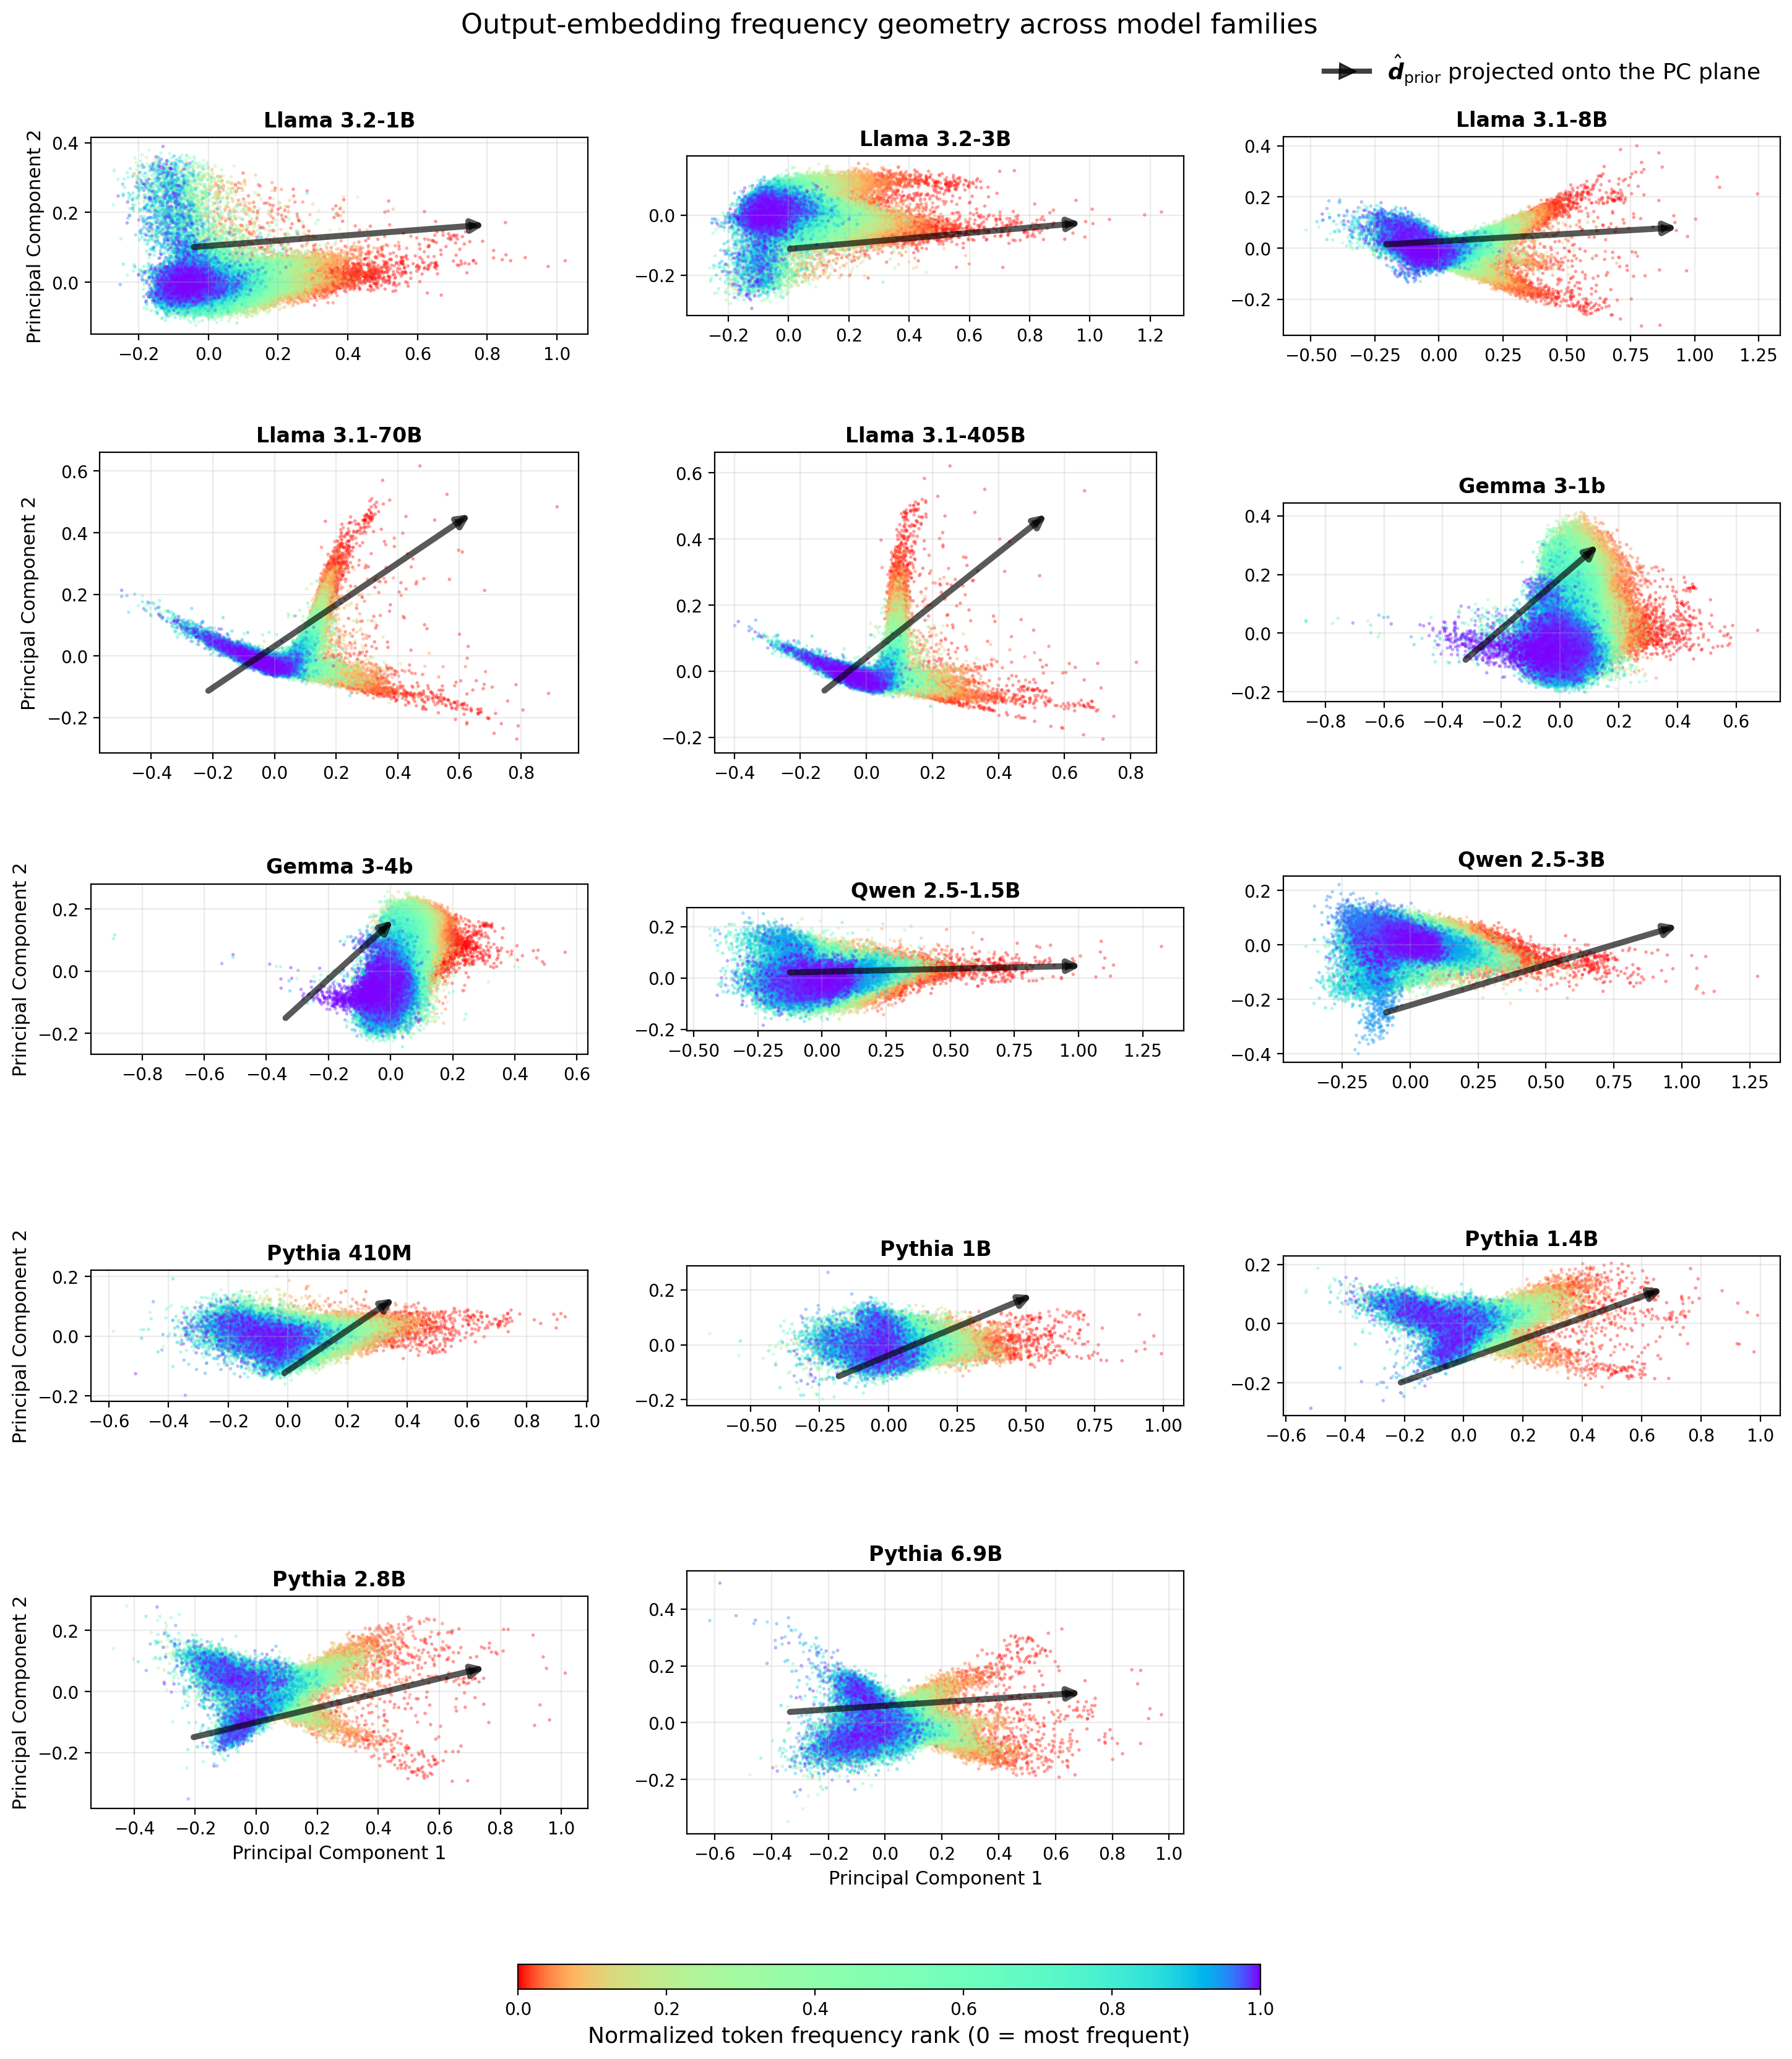

In [17]:
# Multi-model output-embedding geometry for every model in the scaling analysis.
# Llama/Gemma/Qwen reuse the cached W_out and prior fits from Fig. 2. Pythia
# uses its final-checkpoint (step 143k) fig6 prior fit; its W_out is extracted
# once from the locally cached HF checkpoint and saved alongside.
import re

grid_models = [
    "meta-llama/Llama-3.2-1B",
    "meta-llama/Llama-3.2-3B",
    "meta-llama/Llama-3.1-8B",
    "meta-llama/Llama-3.1-70B",
    "meta-llama/Llama-3.1-405B",
    "google/gemma-3-1b-pt",
    "google/gemma-3-4b-pt",
    "Qwen/Qwen2.5-1.5B",
    "Qwen/Qwen2.5-3B",
    # "EleutherAI/pythia-160M",
    "EleutherAI/pythia-410M",
    "EleutherAI/pythia-1B",
    "EleutherAI/pythia-1.4B",
    "EleutherAI/pythia-2.8B",
    "EleutherAI/pythia-6.9B",
]
grid_num_passages = 200
pca_random_seed = 0
pca_sample_size = 8_000
projection_batch_size = 1_024
fig2_cache_dir = DATA_DIR / "fig2_cache"
grid_pca_cache_dir = DATA_DIR / "fig1_multimodel_pca"
grid_pca_cache_dir.mkdir(parents=True, exist_ok=True)
pythia_prior_cache_dir = DATA_DIR / "fig6_lambda_training_dynamics"
pythia_grid_num_passages = 300


def grid_model_tag(name):
    return name.replace("/", "__")


def grid_model_label(name):
    return (
        name.split("/", 1)[-1]
        .replace("Llama-", "Llama ")
        .replace("gemma-", "Gemma ")
        .replace("Qwen", "Qwen ")
        .replace("pythia-", "Pythia ")
        .replace("-pt", "")
    )


def latest_pythia_prior_path(name):
    """(step, path) of the latest cached fig6 prior fit for a Pythia model.

    Fig. 6 caches sometimes use lowercase size suffixes (``pythia-6.9b``) while
    Hugging Face IDs use ``pythia-6.9B``; match case-insensitively.
    """
    short = name.split("/")[-1]
    prefix = f"prior_{short.lower()}_step"
    suffix = f"_N{pythia_grid_num_passages}_T300.npz"
    candidates = sorted(
        (int(re.search(r"_step(\d+)_", path.name).group(1)), path)
        for path in pythia_prior_cache_dir.glob("prior_pythia-*_step*_N*_T300.npz")
        if path.name.lower().startswith(prefix) and path.name.endswith(suffix)
    )
    if not candidates:
        raise FileNotFoundError(f"No Pythia checkpoint prior fits for {name}.")
    return candidates[-1]


def resolve_pythia_w_out_path(short, step):
    """Return an existing W_out cache path, matching size-tag case-insensitively."""
    target = f"wout_{short.lower()}_step{step}_float32.npy"
    for path in pythia_prior_cache_dir.glob("Wout_pythia-*_step*_float32.npy"):
        if path.name.lower() == target:
            return path
    return pythia_prior_cache_dir / f"Wout_{short}_step{step}_float32.npy"


def cache_pythia_w_out(name, step, destination):
    """Extract W_out from the locally cached HF checkpoint and save float32."""
    print(f"Extracting W_out: {grid_model_label(name)} step {step:,}")
    checkpoint = AutoModelForCausalLM.from_pretrained(
        name, revision=f"step{step}", dtype="auto",
    )
    w_out_np = (
        checkpoint.get_output_embeddings().weight.detach().float().cpu().numpy()
    )
    del checkpoint
    partial = destination.with_name(destination.stem + ".partial.npy")
    np.save(partial, w_out_np)
    os.replace(partial, destination)
    print(f"  cached -> {destination.name} ({destination.stat().st_size / 2**20:.0f} MiB)")


def exact_embedding_mean(w_out_memmap, batch_size=2_048):
    total = np.zeros(w_out_memmap.shape[1], dtype=np.float64)
    for start in range(0, w_out_memmap.shape[0], batch_size):
        total += np.asarray(w_out_memmap[start:start + batch_size], dtype=np.float64).sum(axis=0)
    return (total / w_out_memmap.shape[0]).astype(np.float32)


def sampled_pca_basis(w_out_memmap, mean, direction, sample_size, seed):
    """Fit two centered PCs from a deterministic vocabulary sample."""
    rng = np.random.default_rng(seed)
    sample_size = min(int(sample_size), w_out_memmap.shape[0])
    sample_ids = rng.choice(w_out_memmap.shape[0], size=sample_size, replace=False)
    sample = np.asarray(w_out_memmap[sample_ids], dtype=np.float32) - mean
    pca_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(seed)
    sample_tensor = torch.from_numpy(sample).to(pca_device)
    _, _, basis = torch.pca_lowrank(sample_tensor, q=min(4, sample_size), center=False)
    basis = basis[:, :2].float().cpu().numpy()
    del sample_tensor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # PCA signs are arbitrary. Orient each axis so the prior direction has a
    # nonnegative component, making panels visually consistent.
    direction_projection = np.asarray(direction, dtype=np.float32) @ basis
    signs = np.where(direction_projection < 0, -1.0, 1.0).astype(np.float32)
    return basis * signs


def project_embedding_rows(w_out_memmap, token_ids, mean, basis, batch_size):
    """Project selected vocabulary rows in batches without materializing W_out."""
    result = np.empty((len(token_ids), 2), dtype=np.float32)
    pca_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    basis_tensor = torch.from_numpy(np.asarray(basis, dtype=np.float32)).to(pca_device)
    mean_tensor = torch.from_numpy(np.asarray(mean, dtype=np.float32)).to(pca_device)
    for start in range(0, len(token_ids), batch_size):
        stop = min(start + batch_size, len(token_ids))
        block = np.asarray(w_out_memmap[token_ids[start:stop]], dtype=np.float32)
        block_tensor = torch.from_numpy(block).to(pca_device)
        result[start:stop] = ((block_tensor - mean_tensor) @ basis_tensor).cpu().numpy()
        del block_tensor
    del basis_tensor, mean_tensor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


def load_or_compute_grid_geometry(name):
    tag = grid_model_tag(name)
    if "pythia" in name.lower():
        step, metric_path = latest_pythia_prior_path(name)
        short = name.split("/")[-1]
        w_out_path = resolve_pythia_w_out_path(short, step)
        if not w_out_path.exists():
            cache_pythia_w_out(name, step, w_out_path)
        tag = f"{tag}_step{step}"
    else:
        metric_path = fig2_cache_dir / f"panelA_{tag}_N{grid_num_passages}_T300.npz"
        w_out_path = fig2_cache_dir / f"panelA_Wout_{tag}_float32.npy"
    if not metric_path.exists() or not w_out_path.exists():
        raise FileNotFoundError(f"Missing W_out/prior cache for {name}.")

    with np.load(metric_path) as metric_cache:
        d_hat = np.asarray(metric_cache["d_hat"], dtype=np.float32)
        cached_coverage = float(metric_cache["vocab_coverage"])
    coverage_tag = f"{cached_coverage:g}".replace(".", "p")
    geometry_path = grid_pca_cache_dir / (
        f"{tag}_coverage{coverage_tag}_sample{pca_sample_size}_seed{pca_random_seed}.npz"
    )
    if geometry_path.exists():
        with np.load(geometry_path) as cached:
            return {
                "coordinates": np.asarray(cached["coordinates"]),
                "rank_fraction": np.asarray(cached["rank_fraction"]),
                "prior_xy": np.asarray(cached["prior_xy"]),
            }

    print(f"Computing PCA geometry: {grid_model_label(name)}")
    w_out_memmap = np.load(w_out_path, mmap_mode="r")
    if w_out_memmap.ndim != 2 or w_out_memmap.shape[1] != d_hat.size:
        raise ValueError(f"W_out/prior shape mismatch for {name}: {w_out_memmap.shape}, {d_hat.shape}")

    tokenizer = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
    pile_source = "monology/pile-uncopyrighted"
    tokenizer_tag = pile_token_stats.tokenizer_cache_tag(
        tokenizer, vocab_size=w_out_memmap.shape[0]
    )
    frequency_cache_path = DATA_DIR / "token_stats" / (
        f"{tokenizer_tag}__{pile_source.replace('/', '__')}__token_probs.npz"
    )
    probabilities = pile_token_stats.empirical_token_prob(
        tokenizer,
        vocab_size=w_out_memmap.shape[0],
        coverage=cached_coverage,
        dataset_name=pile_source,
        split="train",
        text_column="text",
        cache_path=frequency_cache_path,
        report_every=1_000,
    )
    positive_ids = np.flatnonzero(probabilities > 0)
    frequency_order = np.argsort(probabilities[positive_ids])[::-1]
    ordered_ids = positive_ids[frequency_order]
    rank_fraction = np.linspace(0.0, 1.0, ordered_ids.size, dtype=np.float32)

    mean = exact_embedding_mean(w_out_memmap)
    basis = sampled_pca_basis(
        w_out_memmap, mean, d_hat, pca_sample_size, pca_random_seed
    )
    coordinates = project_embedding_rows(
        w_out_memmap,
        ordered_ids,
        mean,
        basis,
        projection_batch_size,
    )
    prior_xy = d_hat @ basis
    np.savez_compressed(
        geometry_path,
        coordinates=coordinates,
        rank_fraction=rank_fraction,
        prior_xy=prior_xy,
        model_name=name,
        vocab_coverage=cached_coverage,
    )
    return {
        "coordinates": coordinates,
        "rank_fraction": rank_fraction,
        "prior_xy": prior_xy,
    }


# Shared frequency-rank colormap. Rank is normalized within each tokenizer so a
# single colorbar remains meaningful despite different vocabulary sizes.
import matplotlib as mpl
_tan_k_grid = 2.7
_grid_p = np.linspace(0.0, 1.0, 256)
_grid_warp = np.clip(
    0.5 + 0.5 * np.tan(_tan_k_grid * (_grid_p - 0.5)) / np.tan(_tan_k_grid / 2),
    0.0,
    1.0,
)
grid_frequency_cmap = mpl.colors.ListedColormap(plt.get_cmap("rainbow_r")(_grid_warp))
grid_norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)

grid_nrows = int(np.ceil(len(grid_models) / 3))
fig, axes = plt.subplots(grid_nrows, 3, figsize=(15, 3.4 * grid_nrows), dpi=200)
axes = np.atleast_1d(axes).ravel()
for panel_index, (ax, name) in enumerate(zip(axes, grid_models)):
    geometry = load_or_compute_grid_geometry(name)
    coordinates = geometry["coordinates"]
    rank_fraction = geometry["rank_fraction"]
    prior_xy = geometry["prior_xy"]
    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        s=4,
        c=rank_fraction,
        cmap=grid_frequency_cmap,
        norm=grid_norm,
        alpha=0.4,
        linewidths=0,
        rasterized=True,
    )

    prior_norm = np.linalg.norm(prior_xy)
    if prior_norm > 0:
        xlim = ax.get_xlim()
        ylim = ax.get_ylim()
        center = np.asarray([(xlim[0] + xlim[1]) / 2, (ylim[0] + ylim[1]) / 2])
        # Scale the arrow so it spans at most 60% of whichever axis its
        # direction hits first; a fixed fraction of the x-range clipped the
        # steep Gemma arrows out of the panel entirely.
        unit = prior_xy / prior_norm
        arrow_length = 0.6 * min(
            (xlim[1] - xlim[0]) / max(abs(unit[0]), 1e-9),
            (ylim[1] - ylim[0]) / max(abs(unit[1]), 1e-9),
        )
        vector = unit * arrow_length
        start = center - 0.5 * vector
        end = center + 0.5 * vector
        ax.annotate(
            "",
            xy=end,
            xytext=start,
            arrowprops=dict(
                arrowstyle="-|>",
                color="black",
                lw=3.5,
                mutation_scale=14,
                alpha=0.65,
            ),
            annotation_clip=False,
            zorder=5,
        )
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)

    ax.set_title(grid_model_label(name), fontsize=12, fontweight="bold")
    ax.grid(True, alpha=0.25)
    ax.set_aspect("equal", adjustable="box")
    if panel_index // 3 == grid_nrows - 1:
        ax.set_xlabel("Principal Component 1", fontsize=11)
    if panel_index % 3 == 0:
        ax.set_ylabel("Principal Component 2", fontsize=11)

for ax in axes[len(grid_models):]:
    ax.set_visible(False)

# Lay the grid out first, then give the colorbar its own dedicated axes at
# fixed figure coordinates. Reserving space via colorbar(ax=...) and calling
# subplots_adjust afterwards let the bottom row expand over the colorbar.
fig.subplots_adjust(left=0.07, right=0.98, top=0.96, bottom=0.12, wspace=0.2, hspace=0.22)
colorbar_axes = fig.add_axes([0.3, 0.055, 0.4, 0.012])
colorbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=grid_norm, cmap=grid_frequency_cmap),
    cax=colorbar_axes,
    orientation="horizontal",
)
colorbar.set_label(
    "Normalized token frequency rank (0 = most frequent)", fontsize=13
)
colorbar.ax.tick_params(labelsize=10)

# Legend: proxy arrow explaining the black in-panel arrows.
import matplotlib.lines as mlines
arrow_handle = mlines.Line2D(
    [], [], color="black", lw=3.0, marker=">", markersize=9,
    markevery=[-1], alpha=0.75,
)
fig.legend(
    [arrow_handle],
    [r"$\hat{\boldsymbol{d}}_{\mathrm{prior}}$ projected onto the PC plane"],
    loc="upper right",
    bbox_to_anchor=(0.98, 0.985),
    frameon=False,
    fontsize=13,
)

fig.suptitle("Output-embedding frequency geometry across model families", fontsize=16, y=0.995)

export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
grid_export_path = export_dir / "appdx_pca_multimodel.pdf"
fig.savefig(grid_export_path, bbox_inches="tight", dpi=300)
print(f"fig saved at {grid_export_path}")
plt.show()

In [18]:
# Per-model prior-fit statistics for the appendix grid (run the multi-model cell above first).
# Reports R^2, normalized KL, native vocab size, and vocabulary used in the log-linear fit.
import pandas as pd

stats_vocab_coverage = 0.5


def resolve_grid_model_paths(name):
    """Return w_out_path using the same caches as the grid plot."""
    tag = grid_model_tag(name)
    if "pythia" in name.lower():
        step, metric_path = latest_pythia_prior_path(name)
        short = name.split("/")[-1]
        w_out_path = resolve_pythia_w_out_path(short, step)
        if not w_out_path.exists():
            cache_pythia_w_out(name, step, w_out_path)
    else:
        metric_path = fig2_cache_dir / f"panelA_{tag}_N{grid_num_passages}_T300.npz"
        w_out_path = fig2_cache_dir / f"panelA_Wout_{tag}_float32.npy"
    if not metric_path.exists() or not w_out_path.exists():
        raise FileNotFoundError(f"Missing W_out/prior cache for {name}.")
    return w_out_path


def empirical_probs_for_model(name, vocab_size, coverage):
    tokenizer = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
    pile_source = "monology/pile-uncopyrighted"
    tokenizer_tag = pile_token_stats.tokenizer_cache_tag(tokenizer, vocab_size=vocab_size)
    frequency_cache_path = DATA_DIR / "token_stats" / (
        f"{tokenizer_tag}__{pile_source.replace('/', '__')}__token_probs.npz"
    )
    return pile_token_stats.empirical_token_prob(
        tokenizer,
        vocab_size=vocab_size,
        coverage=coverage,
        dataset_name=pile_source,
        split="train",
        text_column="text",
        cache_path=frequency_cache_path,
        report_every=1_000,
    )


stat_rows = []
for name in grid_models:
    w_out_path = resolve_grid_model_paths(name)
    coverage = stats_vocab_coverage
    w_out_memmap = np.load(w_out_path, mmap_mode="r")
    vocab_size = int(w_out_memmap.shape[0])
    print(f"{grid_model_label(name)} (coverage={coverage:g}, vocab={vocab_size:,})")
    probabilities = empirical_probs_for_model(name, vocab_size, coverage)
    # Fit only on the coverage-support rows to avoid materializing huge W_out copies.
    positive_ids = np.flatnonzero(probabilities > 0)
    w_fit = np.asarray(w_out_memmap[positive_ids], dtype=np.float32)
    p_fit = probabilities[positive_ids]
    result = utils.frequency_dipole(
        w_fit,
        p_fit,
        method="optimal_prior",
        exclude_zeros=True,
    )
    row = {
        "model": grid_model_label(name),
        "R2": float(result["r2"]),
        "nKL": float(result["nkl"]),
        "vocab_size": vocab_size,
        "vocab_used": int(result["n_tokens"]),
        "coverage": coverage,
    }
    stat_rows.append(row)
    print(
        f"  R2={row['R2']:.4f}, nKL={row['nKL']:.4f}, "
        f"vocab_used={row['vocab_used']:,}/{row['vocab_size']:,}"
    )
    del w_fit, w_out_memmap

stats_df = pd.DataFrame(stat_rows)
display_df = stats_df.copy()
display_df["R2"] = display_df["R2"].map(lambda x: f"{x:.4f}")
display_df["nKL"] = display_df["nKL"].map(lambda x: f"{x:.4f}")
display_df["vocab_size"] = display_df["vocab_size"].map(lambda x: f"{x:,}")
display_df["vocab_used"] = display_df["vocab_used"].map(lambda x: f"{x:,}")
display_df["coverage"] = display_df["coverage"].map(lambda x: f"{x:g}")
display_df = display_df.rename(
    columns={
        "model": "Model",
        "R2": r"$R^2$",
        "nKL": "nKL",
        "vocab_size": "Vocab size",
        "vocab_used": "Vocab used",
        "coverage": "Coverage",
    }
)
display(display_df)

export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
stats_path = export_dir / "fig1_prior_fit_stats_multimodel.csv"
stats_df.to_csv(stats_path, index=False)
print(f"stats saved at {stats_path}")


Llama 3.2-1B (coverage=0.5, vocab=128,256)
  R2=0.8609, nKL=0.0703, vocab_used=64,128/128,256
Llama 3.2-3B (coverage=0.5, vocab=128,256)
  R2=0.8725, nKL=0.0645, vocab_used=64,128/128,256
Llama 3.1-8B (coverage=0.5, vocab=128,256)
  R2=0.8552, nKL=0.0654, vocab_used=64,128/128,256
Llama 3.1-70B (coverage=0.5, vocab=128,256)
  R2=0.8788, nKL=0.1020, vocab_used=64,128/128,256
Llama 3.1-405B (coverage=0.5, vocab=128,256)
  R2=0.9064, nKL=0.0468, vocab_used=64,128/128,256
Gemma 3-1b (coverage=0.5, vocab=262,144)
  R2=0.7802, nKL=0.0793, vocab_used=131,072/262,144
Gemma 3-4b (coverage=0.5, vocab=262,208)
  R2=0.8347, nKL=0.0671, vocab_used=131,104/262,208
Qwen 2.5-1.5B (coverage=0.5, vocab=151,936)
  R2=0.8060, nKL=0.0734, vocab_used=75,968/151,936
Qwen 2.5-3B (coverage=0.5, vocab=151,936)
  R2=0.8139, nKL=0.0784, vocab_used=75,968/151,936
Pythia 410M (coverage=0.5, vocab=50,304)
  R2=0.7457, nKL=0.0732, vocab_used=25,152/50,304
Pythia 1B (coverage=0.5, vocab=50,304)
  R2=0.7687, nKL=0.0556

,Model,$R^2$,nKL,Vocab size,Vocab used,Coverage
0,Llama 3.2-1B,0.8609,0.0703,"128,256","64,128",0.5
1,Llama 3.2-3B,0.8725,0.0645,"128,256","64,128",0.5
2,Llama 3.1-8B,0.8552,0.0654,"128,256","64,128",0.5
3,Llama 3.1-70B,0.8788,0.1020,"128,256","64,128",0.5
4,Llama 3.1-405B,0.9064,0.0468,"128,256","64,128",0.5
5,Gemma 3-1b,0.7802,0.0793,"262,144","131,072",0.5
6,Gemma 3-4b,0.8347,0.0671,"262,208","131,104",0.5
7,Qwen 2.5-1.5B,0.8060,0.0734,"151,936","75,968",0.5
8,Qwen 2.5-3B,0.8139,0.0784,"151,936","75,968",0.5
9,Pythia 410M,0.7457,0.0732,"50,304","25,152",0.5


stats saved at plot_export/fig1_prior_fit_stats_multimodel.csv


Llama 3.2-1B: coverage=0.7
Llama 3.2-3B: coverage=0.7
Llama 3.1-8B: coverage=0.7
Llama 3.1-70B: coverage=0.7
Llama 3.1-405B: coverage=0.7
Gemma 3-1b: coverage=0.7
Gemma 3-4b: coverage=0.7
Qwen 2.5-1.5B: coverage=0.7
Qwen 2.5-3B: coverage=0.7
Pythia 410M: coverage=0.9, step 143k
Pythia 1B: coverage=0.7, step 143k
Pythia 1.4B: coverage=0.9, step 143k
fig saved at plot_export/appdx_dprior_top_neurons.pdf


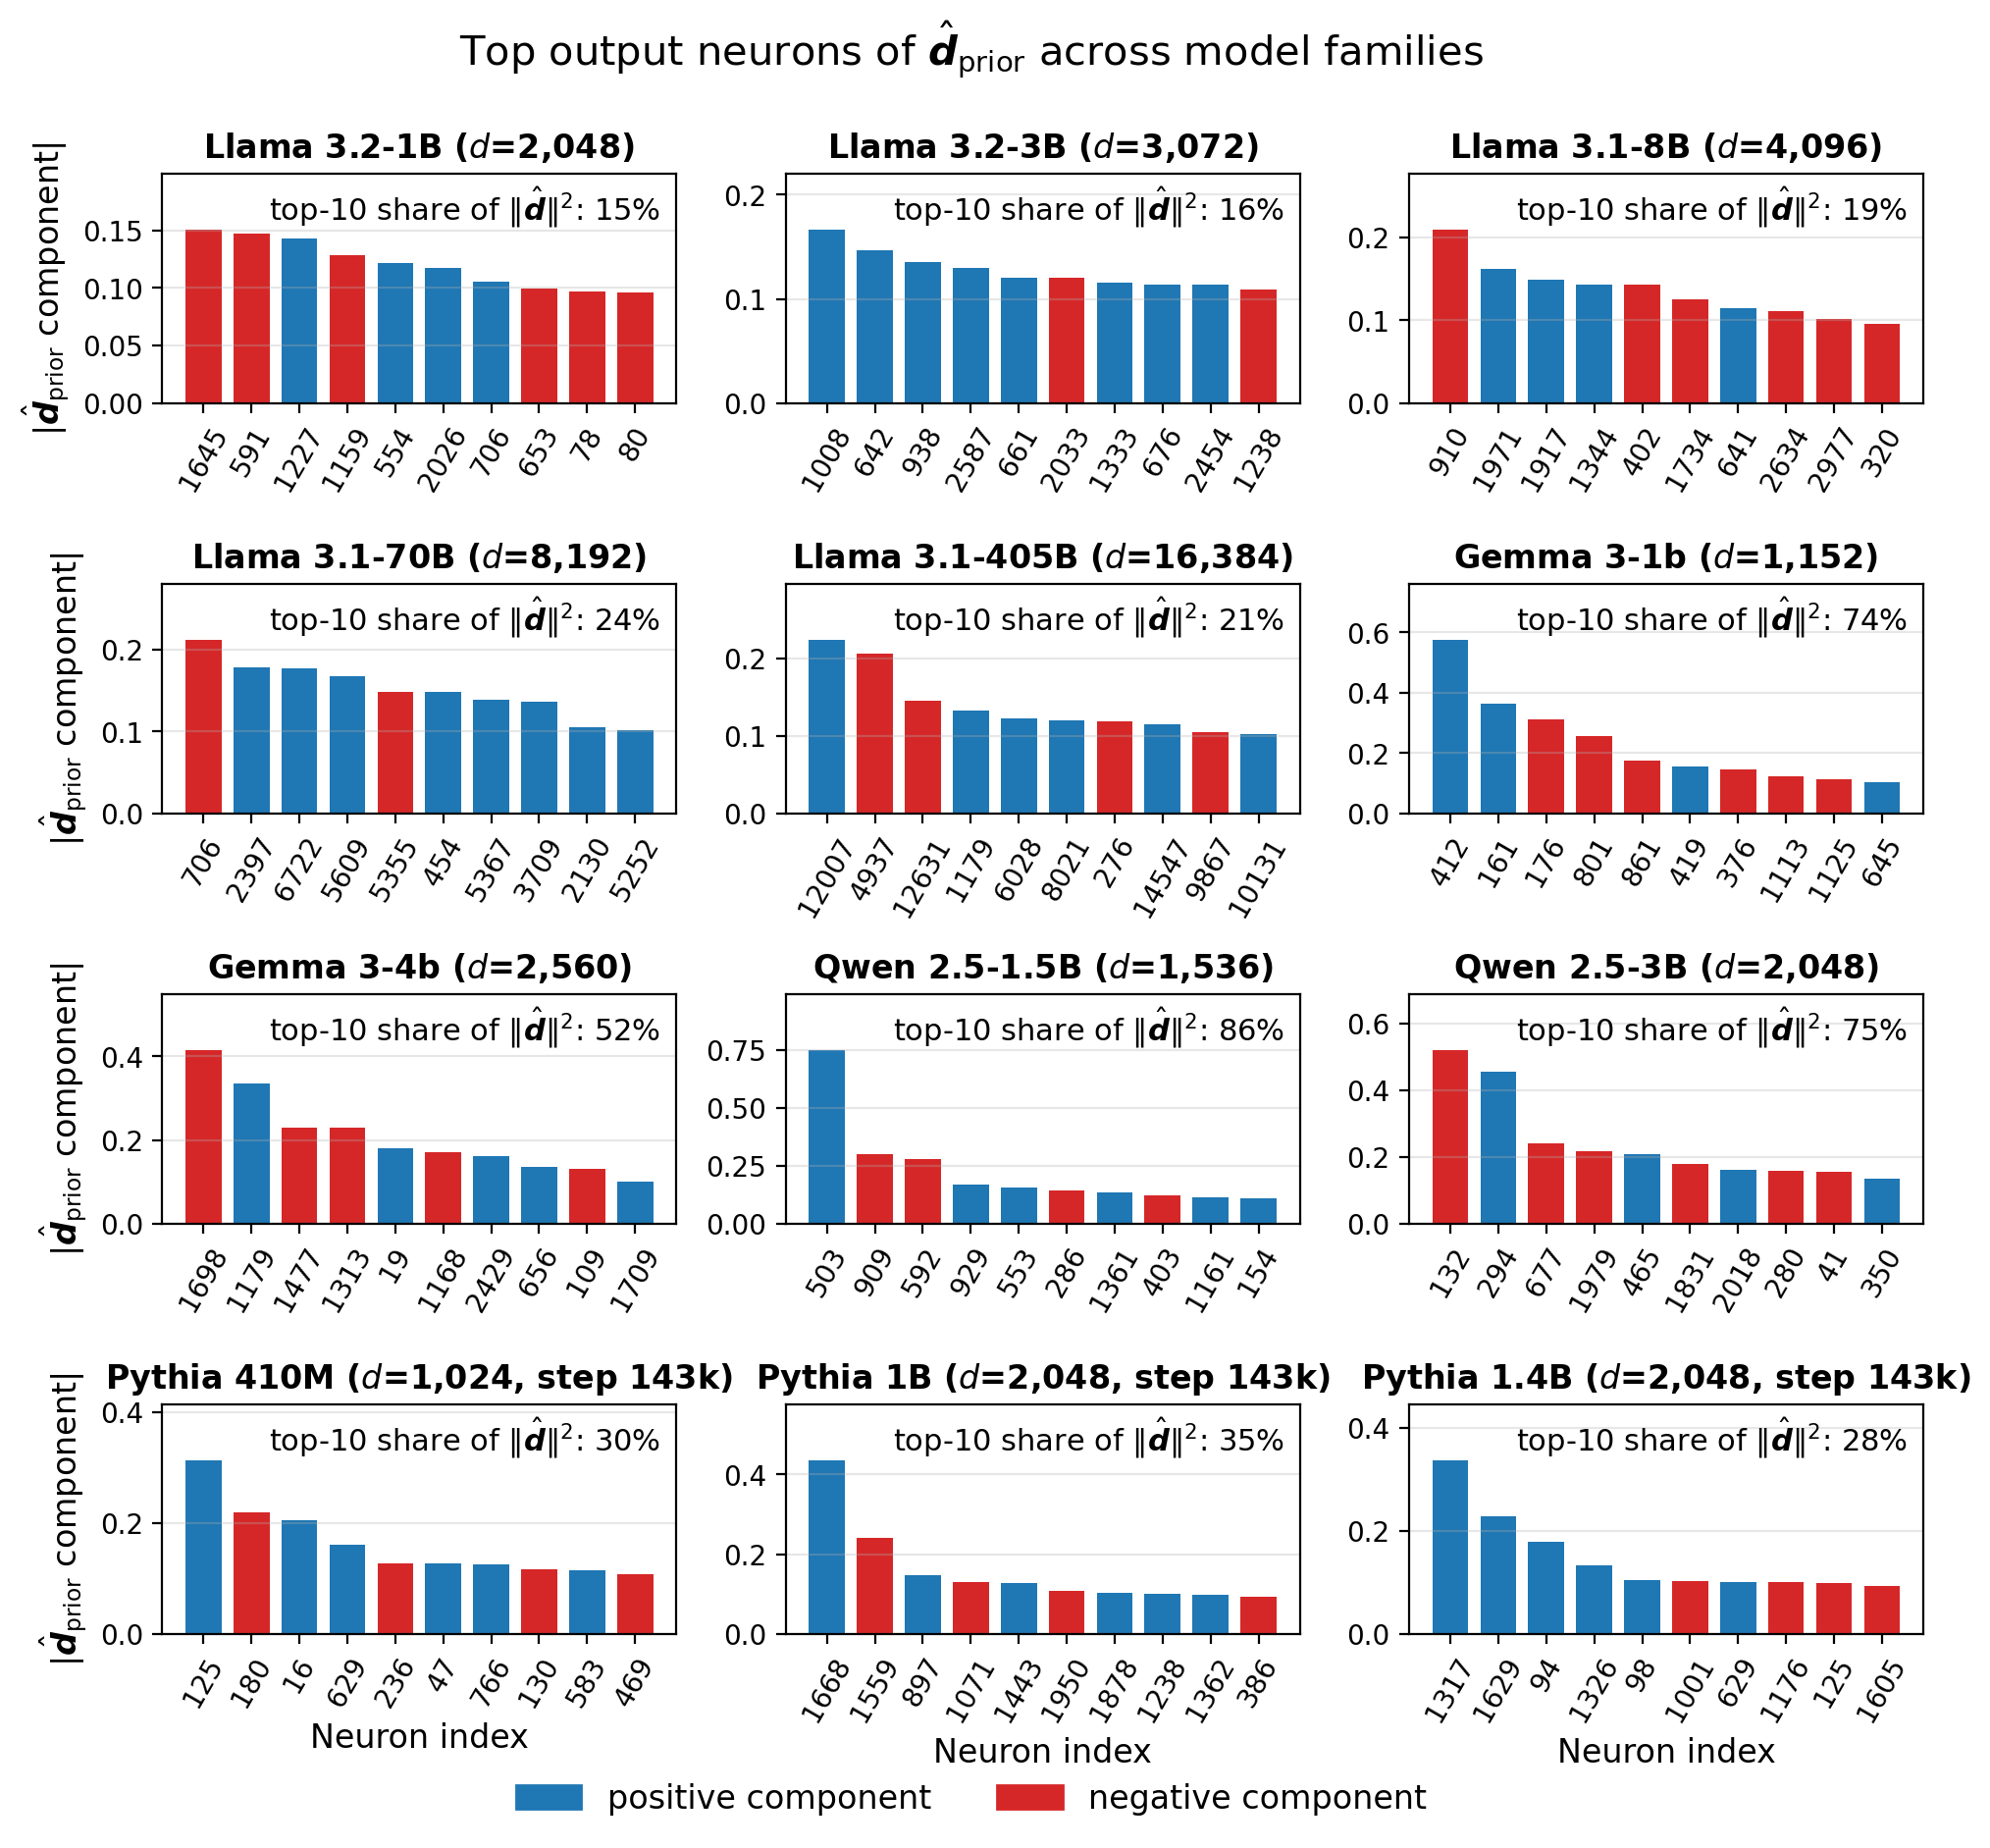

In [19]:
# Ranked bar plots of the neurons d_prior most points at. Self-contained:
# only needs the setup cell (DATA_DIR, np, plt, Path) plus the fig2 prior fits
# (Llama/Gemma/Qwen) and the fig6 final-checkpoint prior fits (Pythia).
import re

FS = 12
top_k = 10
neuron_models = [
    "meta-llama/Llama-3.2-1B",
    "meta-llama/Llama-3.2-3B",
    "meta-llama/Llama-3.1-8B",
    "meta-llama/Llama-3.1-70B",
    "meta-llama/Llama-3.1-405B",
    "google/gemma-3-1b-pt",
    "google/gemma-3-4b-pt",
    "Qwen/Qwen2.5-1.5B",
    "Qwen/Qwen2.5-3B",
    "EleutherAI/pythia-410M",
    "EleutherAI/pythia-1B",
    "EleutherAI/pythia-1.4B",
]
neuron_num_passages = 200
pythia_num_passages = 300
neuron_cache_dir = DATA_DIR / "fig2_cache"
pythia_prior_cache_dir = DATA_DIR / "fig6_lambda_training_dynamics"


def neuron_model_label(name):
    return (
        name.split("/", 1)[-1]
        .replace("Llama-", "Llama ")
        .replace("gemma-", "Gemma ")
        .replace("Qwen", "Qwen ")
        .replace("pythia-", "Pythia ")
        .replace("-pt", "")
    )


def load_neuron_prior_fit(name):
    """Return (d_hat, coverage, note) from the model's cached prior fit."""
    if "pythia" in name.lower():
        # Pythia prior fits are cached per training checkpoint; use the
        # latest (final) step available. Fig. 6 sometimes lowercases the
        # size tag (e.g. pythia-6.9b vs pythia-6.9B).
        tag = name.split("/")[-1]
        prefix = f"prior_{tag.lower()}_step"
        suffix = f"_N{pythia_num_passages}_T300.npz"
        candidates = sorted(
            (int(re.search(r"_step(\d+)_", path.name).group(1)), path)
            for path in pythia_prior_cache_dir.glob("prior_pythia-*_step*_N*_T300.npz")
            if path.name.lower().startswith(prefix) and path.name.endswith(suffix)
        )
        if not candidates:
            raise FileNotFoundError(f"No Pythia checkpoint prior fits for {name}.")
        step, cache_path = candidates[-1]
        note = f"step {step // 1000}k"
    else:
        cache_path = neuron_cache_dir / (
            f"panelA_{name.replace('/', '__')}_N{neuron_num_passages}_T300.npz"
        )
        if not cache_path.exists():
            raise FileNotFoundError(f"Missing Fig. 2 prior-fit cache for {name}.")
        note = None
    with np.load(cache_path) as cache:
        d_hat = np.asarray(cache["d_hat"], dtype=np.float64)
        coverage = float(cache["vocab_coverage"])
    return d_hat, coverage, note


fig, axes = plt.subplots(4, 3, figsize=(10, 9.3), dpi=200, sharey=False)
for panel_index, (ax, name) in enumerate(zip(axes.flat, neuron_models)):
    d_hat, coverage, note = load_neuron_prior_fit(name)
    print(
        f"{neuron_model_label(name)}: coverage={coverage:g}"
        + (f", {note}" if note else "")
    )

    top_ids = np.argsort(np.abs(d_hat))[::-1][:top_k]
    heights = np.abs(d_hat[top_ids])
    # Sign of the component (d_hat is oriented so that lambda > 0 means
    # loading the prior): blue = positive, red = negative.
    colors = ["C0" if d_hat[i] >= 0 else "C3" for i in top_ids]
    top_share = float((d_hat[top_ids] ** 2).sum())

    ax.bar(np.arange(top_k), heights, color=colors, width=0.75)
    ax.set_ylim(0, heights[0] * 1.32)  # headroom for the top-share annotation
    ax.set_xticks(np.arange(top_k))
    ax.set_xticklabels([str(i) for i in top_ids], rotation=60, fontsize=FS - 2)
    ax.tick_params(axis="y", labelsize=FS - 2)
    title_note = f", {note}" if note else ""
    ax.set_title(
        f"{neuron_model_label(name)} ($d$={d_hat.size:,}{title_note})",
        fontsize=FS, fontweight="bold",
    )
    ax.annotate(
        rf"top-{top_k} share of $\|\hat{{\boldsymbol{{d}}}}\|^2$: {top_share:.0%}",
        xy=(0.97, 0.95), xycoords="axes fraction",
        ha="right", va="top", fontsize=FS - 1,
    )
    ax.grid(True, axis="y", alpha=0.3)
    if panel_index // 3 == len(neuron_models) // 3 - 1:
        ax.set_xlabel("Neuron index", fontsize=FS)
    if panel_index % 3 == 0:
        ax.set_ylabel(
            r"$|\hat{\boldsymbol{d}}_{\mathrm{prior}}$ component$|$",
            fontsize=FS,
        )

handles = [
    plt.Rectangle((0, 0), 1, 1, color="C0"),
    plt.Rectangle((0, 0), 1, 1, color="C3"),
]
fig.legend(
    handles, ["positive component", "negative component"],
    loc="lower center", ncol=2, frameon=False, fontsize=FS,
    bbox_to_anchor=(0.5, -0.005),
)
fig.suptitle(
    r"Top output neurons of $\hat{\boldsymbol{d}}_{\mathrm{prior}}$ across model families",
    fontsize=FS + 3, y=0.995,
)
fig.tight_layout(rect=(0, 0.02, 1, 1))

export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
neuron_export_path = export_dir / "appdx_dprior_top_neurons.pdf"
fig.savefig(neuron_export_path, bbox_inches="tight")
print(f"fig saved at {neuron_export_path}")
plt.show()